Baseline Physics-Only PINN

KdV params: a=1.0, b=1.0, c=1.0
Exact solution: A=3.0000, k=0.5000, width~2.0000
Domain: x in [-20.00, 20.00], t in [0.0, 1.0]
BC magnitude at x=+/-L: |u| ~ 2.473e-08
[Check] Residual on exact solution: max=1.371e-06, mean=4.680e-08
Starting Adam optimization...
Epoch     0 | Total 9.853e-01 | PDE 2.255e-03 | IC 6.948e-01 | BC 2.883e-01
Epoch  1000 | Total 3.138e-05 | PDE 2.458e-05 | IC 5.968e-06 | BC 8.362e-07
Epoch  2000 | Total 9.843e-06 | PDE 8.263e-06 | IC 1.352e-06 | BC 2.280e-07
Epoch  3000 | Total 3.932e-06 | PDE 3.342e-06 | IC 5.034e-07 | BC 8.663e-08
Epoch  4000 | Total 2.018e-06 | PDE 1.696e-06 | IC 2.728e-07 | BC 4.891e-08
Adam finished in 247.9 seconds
Starting L-BFGS optimization...
L-BFGS optimization completed

Final Errors:
Rel L2   = 6.853e-04
Rel Linf = 4.798e-04


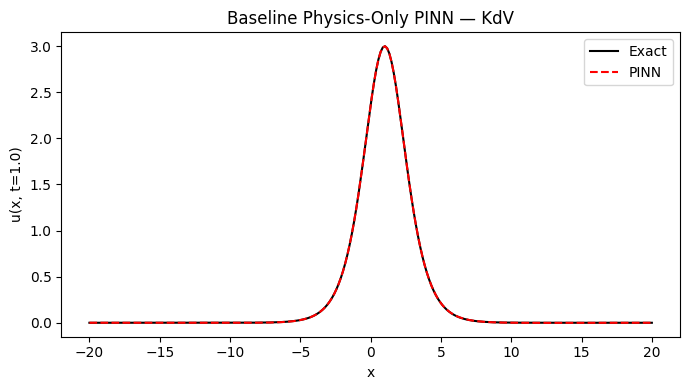

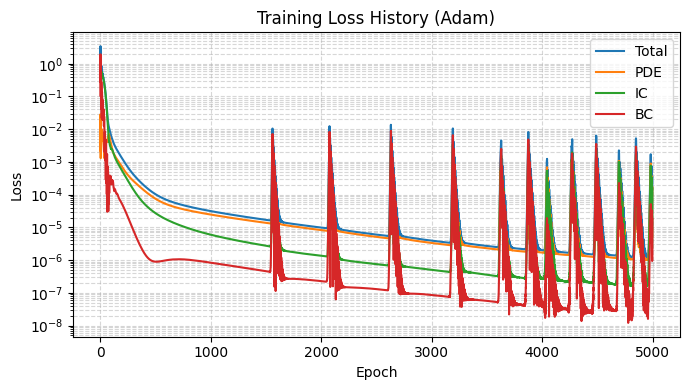

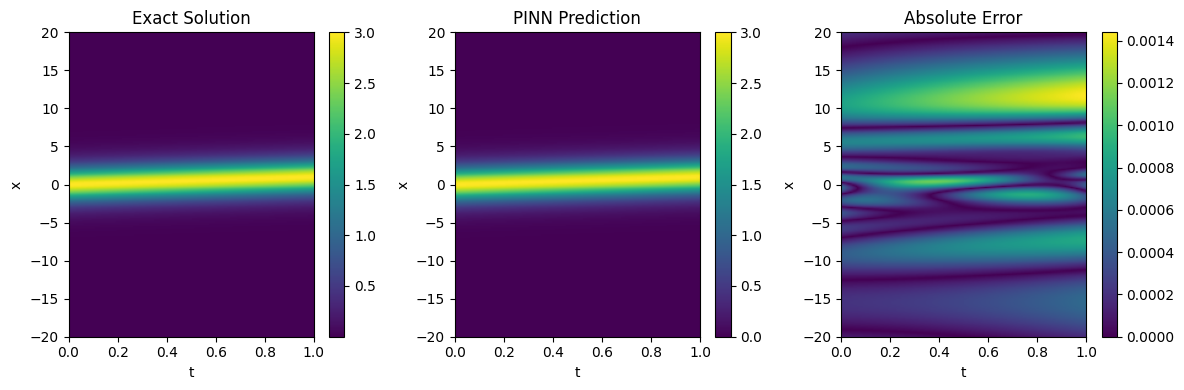

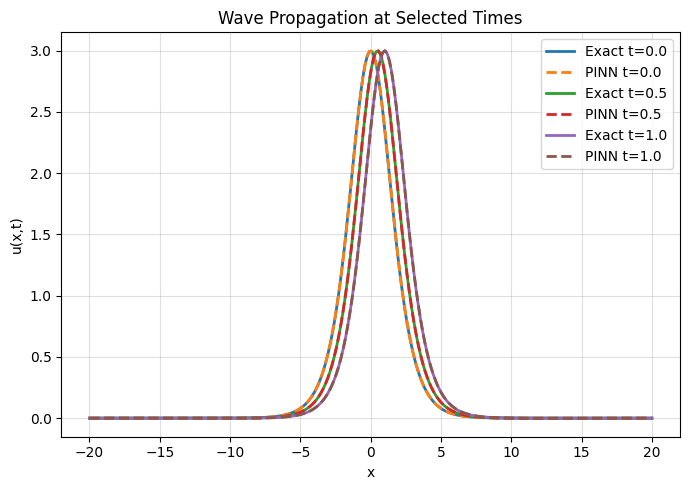

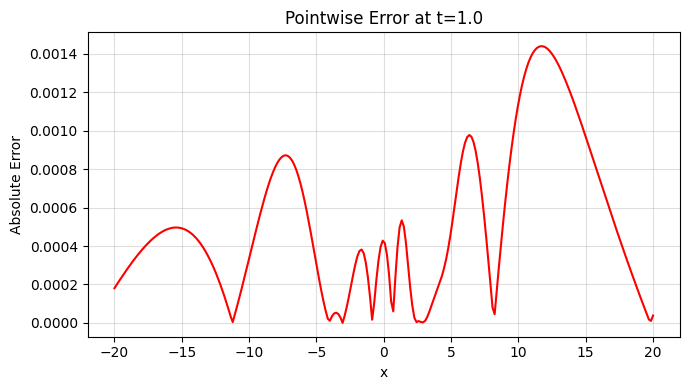

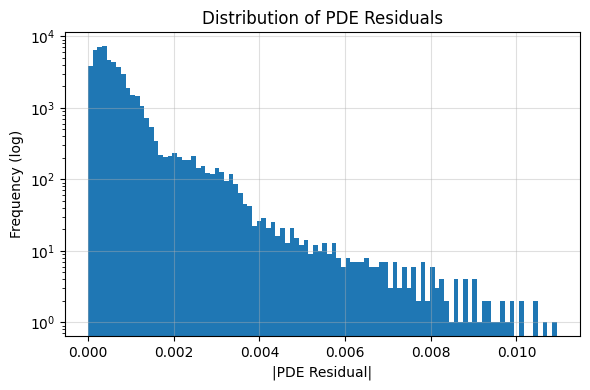

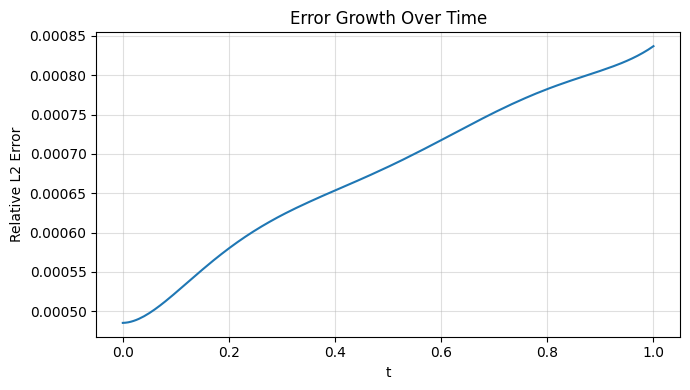

In [ ]:

# ============================================================
# Experiment 1: Baseline Physics-Only PINN
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import time
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Reproducibility & device
# ------------------------------------------------------------
torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 2. KdV parameters
# ------------------------------------------------------------
# Base parameters from the paper's canonical example.
# For the parametric study (Sec. 9), only `c` is varied.
a = 1.0           # nonlinearity coefficient
b = 1.0           # dispersion coefficient
c = 1.0           # wave speed (c > 0)

# Derived quantities of the exact solution
A = 3.0 * c / a                       # amplitude
k = np.sqrt(c / (4.0 * b))            # inverse width

# ------------------------------------------------------------
# 3. Domain definition
# ------------------------------------------------------------
# Soliton has half-width ~ 1/k; choose L = max(20, c*T + 8/k)
# so the soliton stays well inside the domain for t in [0, T].
t_min, t_max = 0.0, 1.0
T_total = t_max - t_min
L = max(20.0, c * T_total + 8.0 / k)
x_min, x_max = -L, L

print(f"KdV params: a={a}, b={b}, c={c}")
print(f"Exact solution: A={A:.4f}, k={k:.4f}, width~{1/k:.4f}")
print(f"Domain: x in [{x_min:.2f}, {x_max:.2f}], t in [{t_min}, {t_max}]")
print(f"BC magnitude at x=+/-L: |u| ~ {A * np.cosh(k*L)**(-2):.3e}")

# ------------------------------------------------------------
# 4. Exact solution (IC, BC, evaluation)
# ------------------------------------------------------------
def exact_solution(x, t):
    # u(x,t) = A * sech^2( k (x - c t) )
    arg = k * (x - c * t)
    # sech^2(y) = 1 / cosh^2(y); clamp for numerical stability at large |y|
    return A / torch.cosh(arg).clamp(min=1e-30) ** 2

# ------------------------------------------------------------
# 5. PINN architecture (8 hidden layers, 80 neurons, tanh)
# ------------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [nn.Linear(2, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
        self.initialize()

    def initialize(self):
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))

model = PINN().to(device)

# ------------------------------------------------------------
# 6. Training data generation
# ------------------------------------------------------------
# Collocation points (PDE residual)
N_f = 10000
x_f = torch.rand(N_f, 1) * (x_max - x_min) + x_min
t_f = torch.rand(N_f, 1) * (t_max - t_min) + t_min

# Initial condition (KdV: only u(x,0); NO u_t(x,0))
N_ic = 512
x_ic = torch.linspace(x_min, x_max, N_ic).view(-1, 1)
t_ic = torch.zeros_like(x_ic)
u_ic = exact_solution(x_ic, t_ic)

# Boundary conditions (Dirichlet, exact values; numerically ~0)
N_bc = 512
t_bc = torch.linspace(t_min, t_max, N_bc).view(-1, 1)
x_bc_left  = torch.full_like(t_bc, x_min)
x_bc_right = torch.full_like(t_bc, x_max)
u_bc_left  = exact_solution(x_bc_left,  t_bc)
u_bc_right = exact_solution(x_bc_right, t_bc)

# Move to device
x_f = x_f.to(device); t_f = t_f.to(device)
x_ic = x_ic.to(device); t_ic = t_ic.to(device); u_ic = u_ic.to(device)
x_bc_left = x_bc_left.to(device); x_bc_right = x_bc_right.to(device)
t_bc = t_bc.to(device)
u_bc_left = u_bc_left.to(device); u_bc_right = u_bc_right.to(device)

# Enable gradients on collocation points for autodiff
x_f.requires_grad_(True)
t_f.requires_grad_(True)

# ------------------------------------------------------------
# 7. PDE residual (KdV:  u_t + a u u_x + b u_xxx = 0)
# ------------------------------------------------------------
def pde_residual(x, t):
    u = model(x, t)

    # First derivatives
    u_t = torch.autograd.grad(
        u, t, grad_outputs=torch.ones_like(u),
        retain_graph=True, create_graph=True
    )[0]
    u_x = torch.autograd.grad(
        u, x, grad_outputs=torch.ones_like(u),
        retain_graph=True, create_graph=True
    )[0]

    # Second and third x-derivatives (for b * u_xxx)
    u_xx = torch.autograd.grad(
        u_x, x, grad_outputs=torch.ones_like(u_x),
        retain_graph=True, create_graph=True
    )[0]
    u_xxx = torch.autograd.grad(
        u_xx, x, grad_outputs=torch.ones_like(u_xx),
        retain_graph=True, create_graph=True
    )[0]

    # KdV residual
    return u_t + a * u * u_x + b * u_xxx

# ------------------------------------------------------------
# 8. Loss function (equal weighting)
# ------------------------------------------------------------
def loss_function():
    f_res = pde_residual(x_f, t_f)
    loss_pde = torch.mean(f_res ** 2)

    u_pred_ic = model(x_ic, t_ic)
    loss_ic = torch.mean((u_pred_ic - u_ic) ** 2)

    u_left  = model(x_bc_left,  t_bc)
    u_right = model(x_bc_right, t_bc)
    loss_bc = torch.mean((u_left  - u_bc_left)  ** 2) + \
              torch.mean((u_right - u_bc_right) ** 2)

    return loss_pde + loss_ic + loss_bc, loss_pde, loss_ic, loss_bc

# ------------------------------------------------------------
# 9. Sanity check: residual on the EXACT solution
#    Must be ~< 1e-6; if not, there is a bug or under-resolution.
# ------------------------------------------------------------
def residual_on_exact(nx=512, nt=128):
    xs = torch.linspace(x_min, x_max, nx, device=device).view(-1, 1)
    ts = torch.linspace(t_min, t_max, nt, device=device).view(-1, 1)
    Xs, Ts = torch.meshgrid(xs.squeeze(), ts.squeeze(), indexing="ij")
    xs = Xs.reshape(-1, 1).requires_grad_(True)
    ts = Ts.reshape(-1, 1).requires_grad_(True)

    u = exact_solution(xs, ts)
    u_t = torch.autograd.grad(u, ts, torch.ones_like(u), create_graph=True)[0]
    u_x = torch.autograd.grad(u, xs, torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, xs, torch.ones_like(u_x), create_graph=True)[0]
    u_xxx = torch.autograd.grad(u_xx, xs, torch.ones_like(u_xx), create_graph=True)[0]
    R = u_t + a * u * u_x + b * u_xxx
    return R.abs().max().item(), R.abs().mean().item()

r_max, r_mean = residual_on_exact()
print(f"[Check] Residual on exact solution: max={r_max:.3e}, mean={r_mean:.3e}")
assert r_max < 1e-4, ("Residual on exact solution is too large. "
                      "Check the solution, parameters, or autodiff chain.")

# ------------------------------------------------------------
# 10. Adam optimizer (5000 epochs)
# ------------------------------------------------------------
loss_history = {"total": [], "pde": [], "ic": [], "bc": []}
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print("Starting Adam optimization...")
start_time = time.time()
for epoch in range(5000):
    optimizer.zero_grad()
    loss, lpde, lic, lbc = loss_function()
    loss.backward()
    optimizer.step()

    loss_history["total"].append(loss.item())
    loss_history["pde"].append(lpde.item())
    loss_history["ic"].append(lic.item())
    loss_history["bc"].append(lbc.item())

    if epoch % 1000 == 0:
        print(f"Epoch {epoch:5d} | Total {loss.item():.3e} | "
              f"PDE {lpde.item():.3e} | IC {lic.item():.3e} | BC {lbc.item():.3e}")
print(f"Adam finished in {time.time() - start_time:.1f} seconds")

# ------------------------------------------------------------
# 11. L-BFGS optimizer (refinement)
# ------------------------------------------------------------
optimizer_lbfgs = torch.optim.LBFGS(
    model.parameters(),
    max_iter=50000,
    tolerance_grad=1e-9,
    tolerance_change=1e-9,
    history_size=50,
    line_search_fn="strong_wolfe",
)

def closure():
    optimizer_lbfgs.zero_grad()
    loss, _, _, _ = loss_function()
    loss.backward()
    return loss

print("Starting L-BFGS optimization...")
optimizer_lbfgs.step(closure)
print("L-BFGS optimization completed")

# ------------------------------------------------------------
# 12. Evaluation on dense grid
# ------------------------------------------------------------
Nx, Nt = 256, 200
x_test = torch.linspace(x_min, x_max, Nx)
t_test = torch.linspace(t_min, t_max, Nt)
X, T = torch.meshgrid(x_test, t_test, indexing="ij")

x_eval = X.reshape(-1, 1).to(device)
t_eval = T.reshape(-1, 1).to(device)

with torch.no_grad():
    u_pred = model(x_eval, t_eval).cpu()
    u_exact = exact_solution(x_eval.cpu(), t_eval.cpu())

error = u_pred - u_exact
rel_l2 = torch.norm(error) / torch.norm(u_exact)
rel_linf = torch.max(torch.abs(error)) / torch.max(torch.abs(u_exact))

print("\nFinal Errors:")
print(f"Rel L2   = {rel_l2.item():.3e}")
print(f"Rel Linf = {rel_linf.item():.3e}")

u_pred_grid = u_pred.view(Nx, Nt).numpy()
u_exact_grid = u_exact.view(Nx, Nt).numpy()

# ------------------------------------------------------------
# 13. Visualization
# ------------------------------------------------------------

# 13a: Solution at final time
plt.figure(figsize=(7, 4))
plt.plot(x_test.numpy(), u_exact_grid[:, -1], 'k-', label='Exact')
plt.plot(x_test.numpy(), u_pred_grid[:, -1], 'r--', label='PINN')
plt.xlabel("x")
plt.ylabel(f"u(x, t={t_max})")
plt.legend()
plt.title("Baseline Physics-Only PINN — KdV")
plt.tight_layout()
plt.show()

# 13b: Training loss history
plt.figure(figsize=(7, 4))
plt.semilogy(loss_history["total"], label="Total")
plt.semilogy(loss_history["pde"], label="PDE")
plt.semilogy(loss_history["ic"], label="IC")
plt.semilogy(loss_history["bc"], label="BC")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training Loss History (Adam)")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 13c: Space-time heatmaps
plt.figure(figsize=(12, 4))
for i, (Z, title) in enumerate(
    [(u_exact_grid, "Exact Solution"),
     (u_pred_grid, "PINN Prediction"),
     (np.abs(u_exact_grid - u_pred_grid), "Absolute Error")], 1
):
    plt.subplot(1, 3, i)
    im = plt.imshow(Z, extent=[t_min, t_max, x_min, x_max],
                    origin="lower", aspect="auto")
    plt.colorbar(im)
    plt.title(title)
    plt.xlabel("t"); plt.ylabel("x")
plt.tight_layout()
plt.show()

# 13d: Cross-sections at multiple times
times_to_plot = [0.0, 0.5, 1.0]
indices = [int(t * (Nt - 1)) for t in times_to_plot]
plt.figure(figsize=(7, 5))
for idx, tval in zip(indices, times_to_plot):
    plt.plot(x_test.numpy(), u_exact_grid[:, idx], linewidth=2, label=f"Exact t={tval}")
    plt.plot(x_test.numpy(), u_pred_grid[:, idx], "--", linewidth=2, label=f"PINN t={tval}")
plt.xlabel("x"); plt.ylabel("u(x,t)")
plt.legend(); plt.title("Wave Propagation at Selected Times")
plt.grid(alpha=0.4); plt.tight_layout(); plt.show()

# 13e: Pointwise error at final time
final_error = np.abs(u_exact_grid[:, -1] - u_pred_grid[:, -1])
plt.figure(figsize=(7, 4))
plt.plot(x_test.numpy(), final_error, 'r')
plt.xlabel("x"); plt.ylabel("Absolute Error")
plt.title(f"Pointwise Error at t={t_max}")
plt.grid(alpha=0.4); plt.tight_layout(); plt.show()

# 13f: PDE residual histogram (on a fresh evaluation grid)
x_eval_grad = x_eval.clone().detach().requires_grad_(True)
t_eval_grad = t_eval.clone().detach().requires_grad_(True)
f_res_eval = pde_residual(x_eval_grad, t_eval_grad).cpu().detach().numpy()

plt.figure(figsize=(6, 4))
plt.hist(np.abs(f_res_eval), bins=100, log=True)
plt.xlabel("|PDE Residual|"); plt.ylabel("Frequency (log)")
plt.title("Distribution of PDE Residuals")
plt.grid(alpha=0.4); plt.tight_layout(); plt.show()

# 13g: Error growth over time
time_error = (np.linalg.norm(u_exact_grid - u_pred_grid, axis=0)
              / np.linalg.norm(u_exact_grid, axis=0))
plt.figure(figsize=(7, 4))
plt.plot(t_test.numpy(), time_error)
plt.xlabel("t"); plt.ylabel("Relative L2 Error")
plt.title("Error Growth Over Time")
plt.grid(alpha=0.4); plt.tight_layout(); plt.show()

CNN-PINN with sparse observations

In [ ]:
import torch
torch.cuda.empty_cache()

[Check] Residual on exact solution: max=1.371e-06
Starting Adam optimization...
Epoch     0 | Total 1.694e+01 | Data 6.344e-01 | PDE 1.824e-02 | IC 7.065e-01 | BC 3.516e-01
Epoch  1000 | Total 1.226e-03 | Data 6.455e-05 | PDE 3.666e-04 | IC 1.951e-05 | BC 1.896e-06
Epoch  2000 | Total 4.239e-04 | Data 2.014e-05 | PDE 1.611e-04 | IC 5.514e-06 | BC 6.260e-07
Epoch  3000 | Total 1.615e-04 | Data 7.091e-06 | PDE 6.833e-05 | IC 2.013e-06 | BC 2.168e-07
Epoch  4000 | Total 1.315e-03 | Data 3.879e-05 | PDE 4.149e-05 | IC 3.711e-05 | BC 5.144e-05
Adam finished in 193.9 seconds
Starting L-BFGS optimization...
L-BFGS optimization completed

Final Errors:
Rel L2   = 2.245e-03
Rel Linf = 2.077e-02


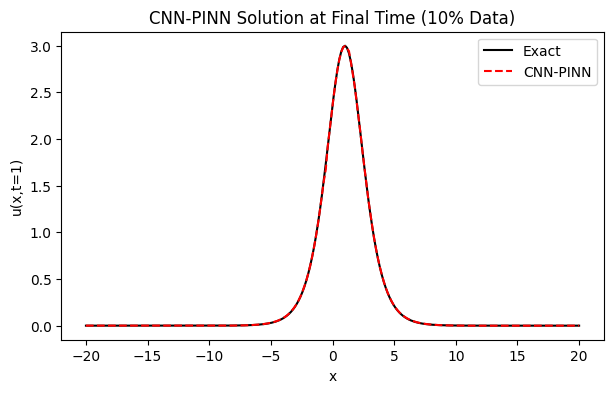

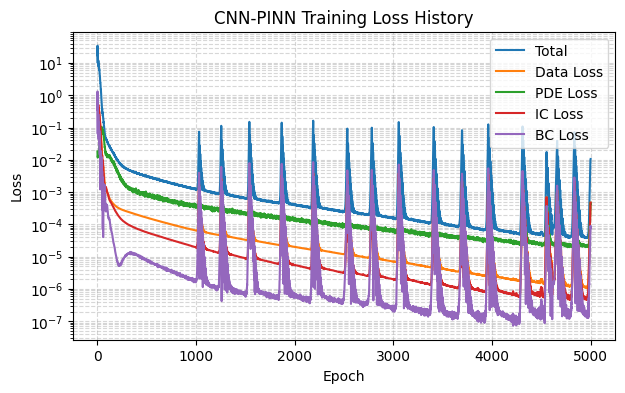

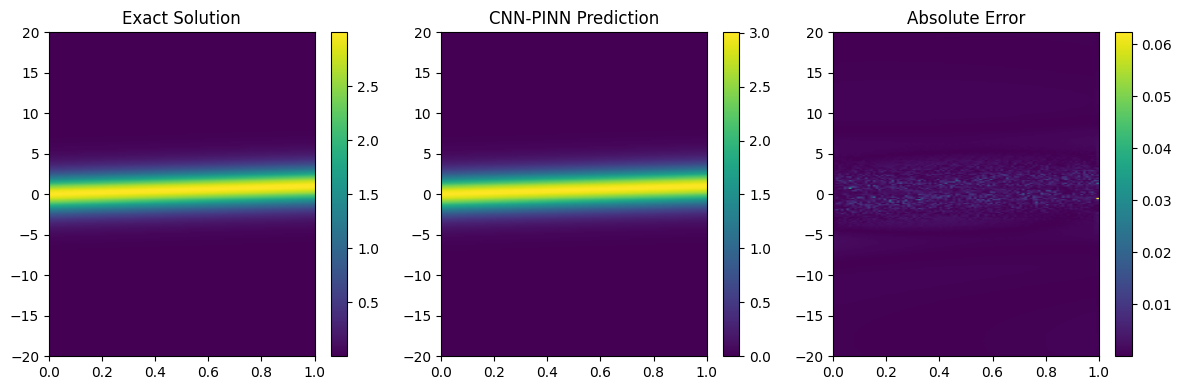

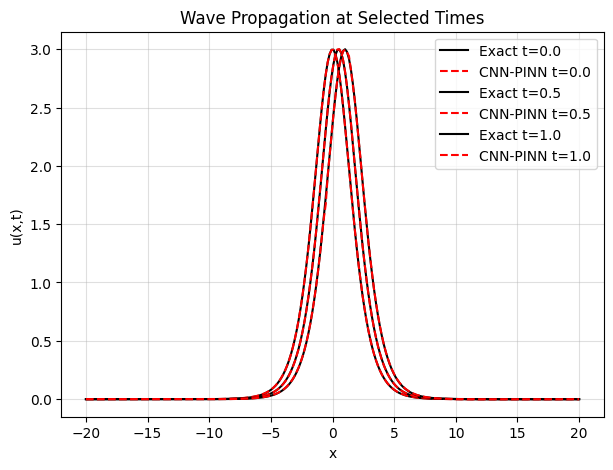

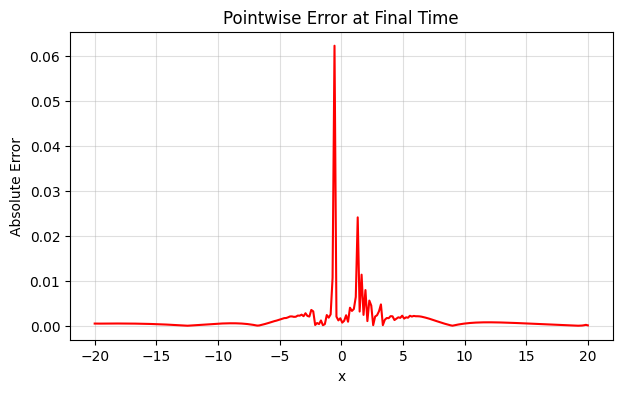

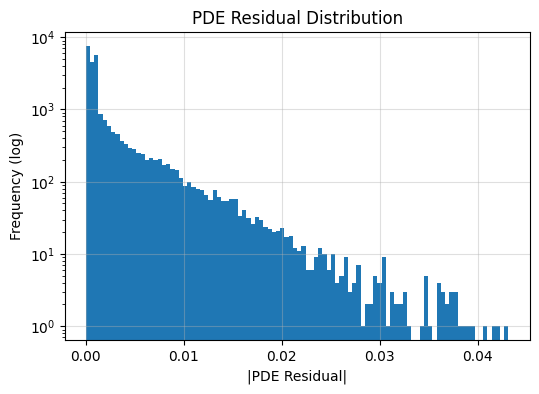

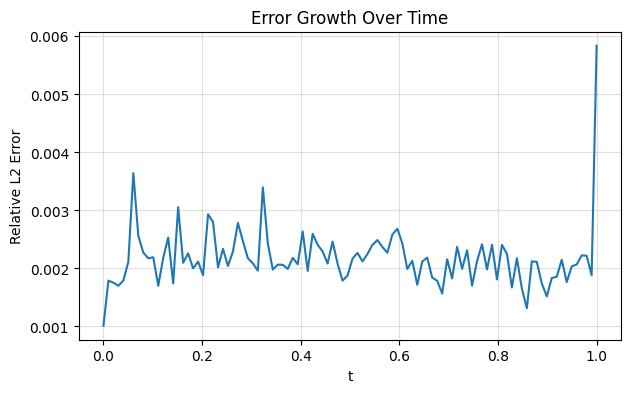

In [ ]:

# ============================================================
# Experiment 2: CNN-PINN with Sparse Observations (KdV)
# Korteweg–de Vries Equation: u_t + a u u_x + b u_xxx = 0
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Reproducibility & device
# ------------------------------------------------------------
torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 2. KdV Parameters & Domain
# ------------------------------------------------------------
a = 1.0
b = 1.0
c = 1.0
A = 3.0 * c / a
k = np.sqrt(c / (4.0 * b))

t_min, t_max = 0.0, 1.0
T_total = t_max - t_min
L = max(20.0, c * T_total + 8.0 / k)
x_min, x_max = -L, L

def exact_solution(x, t):
    arg = k * (x - c * t)
    return A / torch.cosh(arg).clamp(min=1e-30) ** 2

# ------------------------------------------------------------
# 3. Generate sparse observational data (10% of grid)
# ------------------------------------------------------------
# High-res grid needed to resolve the soliton
Nx, Nt = 256, 100
x_grid = torch.linspace(x_min, x_max, Nx)
t_grid = torch.linspace(t_min, t_max, Nt)
X, T = torch.meshgrid(x_grid, t_grid, indexing="ij")
U_exact = exact_solution(X, T)

num_obs = int(0.1 * Nx * Nt)
obs_indices = np.random.choice(Nx*Nt, num_obs, replace=False)
obs_x = X.reshape(-1,1)[obs_indices].to(device)
obs_t = T.reshape(-1,1)[obs_indices].to(device)
obs_u = U_exact.reshape(-1,1)[obs_indices].to(device)

# CNN input: 2D observation grid (zeros in unobserved locations)
U_obs_grid = torch.zeros_like(U_exact).float().to(device)
U_obs_grid.reshape(-1)[obs_indices] = obs_u.flatten()
U_obs_cnn = U_obs_grid.unsqueeze(0).unsqueeze(0)  # shape (1,1,Nx,Nt)

# ------------------------------------------------------------
# 4. CNN Encoder
# ------------------------------------------------------------
class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv4 = nn.Conv2d(64, 64, 3, padding=1)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        return x

cnn_encoder = CNNEncoder().to(device)

# ------------------------------------------------------------
# 5. PINN Decoder
# ------------------------------------------------------------
class PINNDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [nn.Linear(2 + 64, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80,80), nn.Tanh()]
        layers.append(nn.Linear(80,1))
        self.net = nn.Sequential(*layers)
        self.initialize()

    def initialize(self):
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x, t, latent_features):
        return self.net(torch.cat([x, t, latent_features], dim=1))

pinn_decoder = PINNDecoder().to(device)

# ------------------------------------------------------------
# 6. PDE residual (KdV)
# ------------------------------------------------------------
def pde_residual(x, t, latent_features):
    u = pinn_decoder(x, t, latent_features)

    u_t = torch.autograd.grad(u, t, torch.ones_like(u), retain_graph=True, create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), retain_graph=True, create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), retain_graph=True, create_graph=True)[0]
    u_xxx = torch.autograd.grad(u_xx, x, torch.ones_like(u_xx), retain_graph=True, create_graph=True)[0]

    # KdV: u_t + a*u*u_x + b*u_xxx = 0
    return u_t + a * u * u_x + b * u_xxx

# ------------------------------------------------------------
# 7. Verification Check (Must pass before training)
# ------------------------------------------------------------
def check_exact_residual(nx=512, nt=128):
    xs = torch.linspace(x_min, x_max, nx, device=device).view(-1, 1)
    ts = torch.linspace(t_min, t_max, nt, device=device).view(-1, 1)
    Xs, Ts = torch.meshgrid(xs.squeeze(), ts.squeeze(), indexing="ij")
    xs = Xs.reshape(-1, 1).requires_grad_(True)
    ts = Ts.reshape(-1, 1).requires_grad_(True)

    u = exact_solution(xs, ts)
    u_t = torch.autograd.grad(u, ts, torch.ones_like(u), create_graph=True)[0]
    u_x = torch.autograd.grad(u, xs, torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, xs, torch.ones_like(u_x), create_graph=True)[0]
    u_xxx = torch.autograd.grad(u_xx, xs, torch.ones_like(u_xx), create_graph=True)[0]

    R = u_t + a * u * u_x + b * u_xxx
    return R.abs().max().item()

r_max = check_exact_residual()
print(f"[Check] Residual on exact solution: max={r_max:.3e}")
assert r_max < 1e-4, "Exact solution does not satisfy the PDE! Check your parameters."

# ------------------------------------------------------------
# 8. Latent feature sampling
# ------------------------------------------------------------
def sample_latent_features(x, t):
    with torch.no_grad():
        cnn_features = cnn_encoder(U_obs_cnn)  # (1,64,Nx,Nt)
    x_norm = ((x - x_min) / (x_max - x_min)) * 2 - 1
    t_norm = ((t - t_min) / (t_max - t_min)) * 2 - 1
    grid_coords = torch.cat([t_norm, x_norm], dim=1)
    N_points = x.shape[0]
    grid = grid_coords.view(1, N_points, 1, 2)
    latent = F.grid_sample(cnn_features, grid, align_corners=True)
    return latent.squeeze().permute(1,0)

# ------------------------------------------------------------
# 9. Training data (IC, BC, Collocation)
# ------------------------------------------------------------
N_ic = 512
x_ic = torch.linspace(x_min, x_max, N_ic).view(-1,1).to(device)
t_ic = torch.zeros_like(x_ic).to(device)
u_ic = exact_solution(x_ic, t_ic).to(device)

N_bc = 512
t_bc = torch.linspace(t_min, t_max, N_bc).view(-1,1).to(device)
x_bc_left = torch.full_like(t_bc, x_min).to(device)
x_bc_right = torch.full_like(t_bc, x_max).to(device)
u_bc_left = exact_solution(x_bc_left, t_bc).to(device)
u_bc_right = exact_solution(x_bc_right, t_bc).to(device)

x_f_full = X.reshape(-1,1).to(device)
t_f_full = T.reshape(-1,1).to(device)
x_f_full.requires_grad_(True)
t_f_full.requires_grad_(True)

# ------------------------------------------------------------
# 10. Loss function
# ------------------------------------------------------------
def loss_function(N_f_epoch=5000):
    # Sample PDE points
    idx_f = np.random.choice(x_f_full.shape[0], N_f_epoch, replace=False)
    x_f = x_f_full[idx_f].clone().detach().requires_grad_(True)
    t_f = t_f_full[idx_f].clone().detach().requires_grad_(True)

    latent_f = sample_latent_features(x_f, t_f).detach()
    latent_ic = sample_latent_features(x_ic, t_ic).detach()
    latent_bc_left = sample_latent_features(x_bc_left, t_bc).detach()
    latent_bc_right = sample_latent_features(x_bc_right, t_bc).detach()

    # PDE loss
    f_res = pde_residual(x_f, t_f, latent_f)
    loss_pde = torch.mean(f_res**2)

    # IC/BC loss
    u_pred_ic = pinn_decoder(x_ic, t_ic, latent_ic)
    u_pred_bc_left = pinn_decoder(x_bc_left, t_bc, latent_bc_left)
    u_pred_bc_right = pinn_decoder(x_bc_right, t_bc, latent_bc_right)
    loss_ic = torch.mean((u_pred_ic - u_ic)**2)
    loss_bc = torch.mean((u_pred_bc_left - u_bc_left)**2) + torch.mean((u_pred_bc_right - u_bc_right)**2)

    # Data loss (on sparse observations)
    latent_obs = sample_latent_features(obs_x, obs_t)
    u_pred_obs = pinn_decoder(obs_x, obs_t, latent_obs)
    loss_data = torch.mean((u_pred_obs - obs_u)**2)

    # Weighting
    total_loss = 10.0*loss_data + 1.0*loss_pde + 10.0*(loss_ic + loss_bc)
    return total_loss, loss_data, loss_pde, loss_ic, loss_bc

# ------------------------------------------------------------
# 11. Adam Optimizer
# ------------------------------------------------------------
loss_history = {"total":[],"data":[],"pde":[],"ic":[],"bc":[]}
optimizer = torch.optim.Adam(list(pinn_decoder.parameters()) + list(cnn_encoder.parameters()), lr=1e-3)

print("Starting Adam optimization...")
start_time = time.time()
for epoch in range(5000):
    optimizer.zero_grad()
    loss, ldata, lpde, lic, lbc = loss_function()
    loss.backward()
    optimizer.step()

    loss_history["total"].append(loss.item())
    loss_history["data"].append(ldata.item())
    loss_history["pde"].append(lpde.item())
    loss_history["ic"].append(lic.item())
    loss_history["bc"].append(lbc.item())

    if epoch % 1000 == 0:
        print(f"Epoch {epoch:5d} | Total {loss.item():.3e} | Data {ldata.item():.3e} | PDE {lpde.item():.3e} | IC {lic.item():.3e} | BC {lbc.item():.3e}")

print(f"Adam finished in {time.time()-start_time:.1f} seconds")

# ------------------------------------------------------------
# 12. L-BFGS Optimizer (Refinement)
# ------------------------------------------------------------
optimizer_lbfgs = torch.optim.LBFGS(
    list(pinn_decoder.parameters()) + list(cnn_encoder.parameters()),
    max_iter=50000, tolerance_grad=1e-9, tolerance_change=1e-9,
    history_size=50, line_search_fn="strong_wolfe"
)

def closure():
    optimizer_lbfgs.zero_grad()
    loss, _, _, _, _ = loss_function()
    loss.backward()
    return loss

print("Starting L-BFGS optimization...")
optimizer_lbfgs.step(closure)
print("L-BFGS optimization completed")

# ------------------------------------------------------------
# 13. Evaluation & Metrics
# ------------------------------------------------------------
with torch.no_grad():
    latent_eval = sample_latent_features(x_f_full, t_f_full)
    u_pred = pinn_decoder(x_f_full, t_f_full, latent_eval).cpu()
    u_exact = exact_solution(x_f_full.cpu(), t_f_full.cpu())

error = u_pred - u_exact
rel_l2 = torch.norm(error)/torch.norm(u_exact)
rel_linf = torch.max(torch.abs(error))/torch.max(torch.abs(u_exact))

print("\nFinal Errors:")
print(f"Rel L2   = {rel_l2.item():.3e}")
print(f"Rel Linf = {rel_linf.item():.3e}")

u_pred_grid = u_pred.view(Nx,Nt).numpy()
u_exact_grid = u_exact.view(Nx,Nt).numpy()

# ------------------------------------------------------------
# 14. Visualization
# ------------------------------------------------------------
# 14a: Solution at final time
plt.figure(figsize=(7,4))
plt.plot(x_grid.numpy(), u_exact_grid[:,-1],'k-',label='Exact')
plt.plot(x_grid.numpy(), u_pred_grid[:,-1],'r--',label='CNN-PINN')
plt.xlabel("x"); plt.ylabel("u(x,t=1)")
plt.legend(); plt.title("CNN-PINN Solution at Final Time (10% Data)"); plt.show()

# 14b: Training loss history
plt.figure(figsize=(7,4))
plt.semilogy(loss_history["total"], label="Total")
plt.semilogy(loss_history["data"], label="Data Loss")
plt.semilogy(loss_history["pde"], label="PDE Loss")
plt.semilogy(loss_history["ic"], label="IC Loss")
plt.semilogy(loss_history["bc"], label="BC Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.legend(); plt.title("CNN-PINN Training Loss History")
plt.grid(True,which="both",ls="--",alpha=0.5); plt.show()

# 14c: Space-time heatmaps
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(u_exact_grid, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto")
plt.colorbar(); plt.title("Exact Solution")
plt.subplot(1,3,2)
plt.imshow(u_pred_grid, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto")
plt.colorbar(); plt.title("CNN-PINN Prediction")
plt.subplot(1,3,3)
plt.imshow(np.abs(u_exact_grid-u_pred_grid), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto")
plt.colorbar(); plt.title("Absolute Error")
plt.tight_layout(); plt.show()

# 14d: Cross-sections at multiple times
times_to_plot = [0.0,0.5,1.0]
indices = [int(t*(Nt-1)) for t in times_to_plot]
plt.figure(figsize=(7,5))
for idx,tval in zip(indices,times_to_plot):
    plt.plot(x_grid.numpy(), u_exact_grid[:,idx],'k-',label=f"Exact t={tval}")
    plt.plot(x_grid.numpy(), u_pred_grid[:,idx],'r--',label=f"CNN-PINN t={tval}")
plt.xlabel("x"); plt.ylabel("u(x,t)"); plt.legend()
plt.title("Wave Propagation at Selected Times"); plt.grid(alpha=0.4); plt.show()

# 14e: Pointwise error at final time
final_error = np.abs(u_exact_grid[:,-1]-u_pred_grid[:,-1])
plt.figure(figsize=(7,4))
plt.plot(x_grid.numpy(), final_error,'r')
plt.xlabel("x"); plt.ylabel("Absolute Error")
plt.title("Pointwise Error at Final Time"); plt.grid(alpha=0.4); plt.show()

# 14f: PDE residual histogram
x_eval_grad = x_f_full.clone().detach().requires_grad_(True)
t_eval_grad = t_f_full.clone().detach().requires_grad_(True)
# CRITICAL FIX: .detach() added here to prevent the cudnn_grid_sampler_backward crash
latent_eval_for_pde = sample_latent_features(x_eval_grad, t_eval_grad).detach()
f_res_eval = pde_residual(x_eval_grad, t_eval_grad, latent_eval_for_pde).cpu().detach().numpy()

plt.figure(figsize=(6,4))
plt.hist(np.abs(f_res_eval), bins=100, log=True)
plt.xlabel("|PDE Residual|"); plt.ylabel("Frequency (log)")
plt.title("PDE Residual Distribution"); plt.grid(alpha=0.4); plt.show()

# 14g: Error growth over time
time_error = np.linalg.norm(u_exact_grid-u_pred_grid,axis=0)/np.linalg.norm(u_exact_grid,axis=0)
plt.figure(figsize=(7,4))
plt.plot(t_grid.numpy(), time_error)
plt.xlabel("t"); plt.ylabel("Relative L2 Error")
plt.title("Error Growth Over Time"); plt.grid(alpha=0.4); plt.show()

Robustness Under Noisy


=== Noise level: 1% ===
Epoch     0 | Total 6.342e+00 | Data 6.323e-01 | PDE 1.830e-02
Epoch  1000 | Total 9.659e-03 | Data 9.508e-04 | PDE 1.513e-04
Epoch  2000 | Total 9.470e-03 | Data 9.391e-04 | PDE 7.940e-05
Epoch  3000 | Total 9.394e-03 | Data 9.339e-04 | PDE 5.457e-05
Epoch  4000 | Total 1.478e-02 | Data 1.462e-03 | PDE 1.555e-04
Final CNN-PINN Rel L2: 1.177e-02
Final Physics-only Rel L2: 9.846e-01


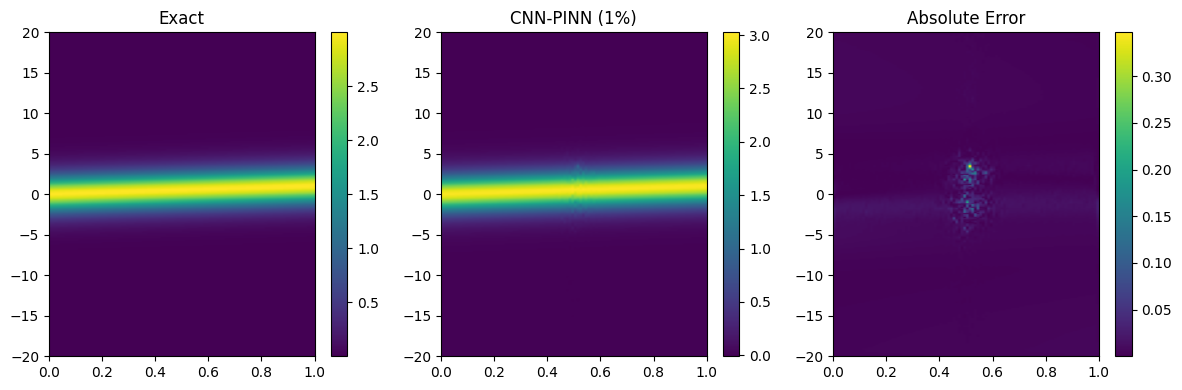

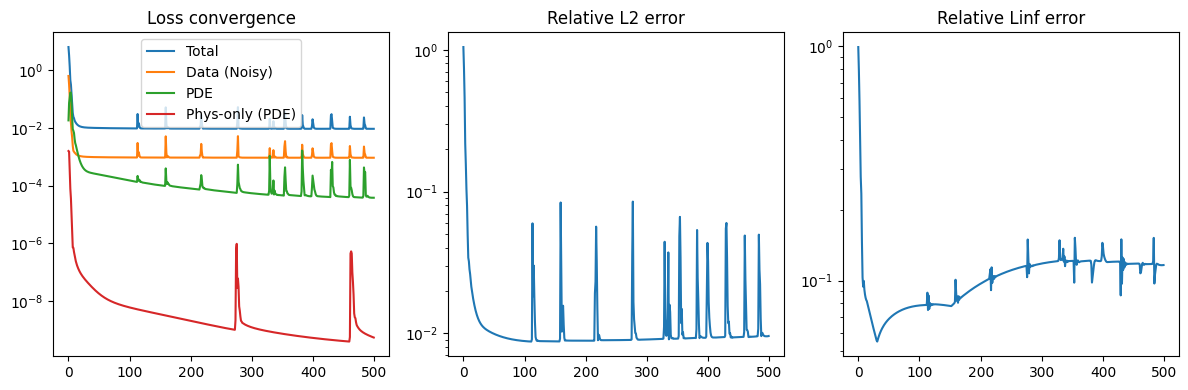


=== Noise level: 5% ===
Epoch     0 | Total 6.353e+00 | Data 6.352e-01 | PDE 3.895e-04
Epoch  1000 | Total 2.119e-01 | Data 2.115e-02 | PDE 4.658e-04
Epoch  2000 | Total 2.104e-01 | Data 2.099e-02 | PDE 5.209e-04
Epoch  3000 | Total 3.066e-01 | Data 3.058e-02 | PDE 8.138e-04
Epoch  4000 | Total 2.156e-01 | Data 2.148e-02 | PDE 7.762e-04
Final CNN-PINN Rel L2: 5.574e-02
Final Physics-only Rel L2: 1.004e+00


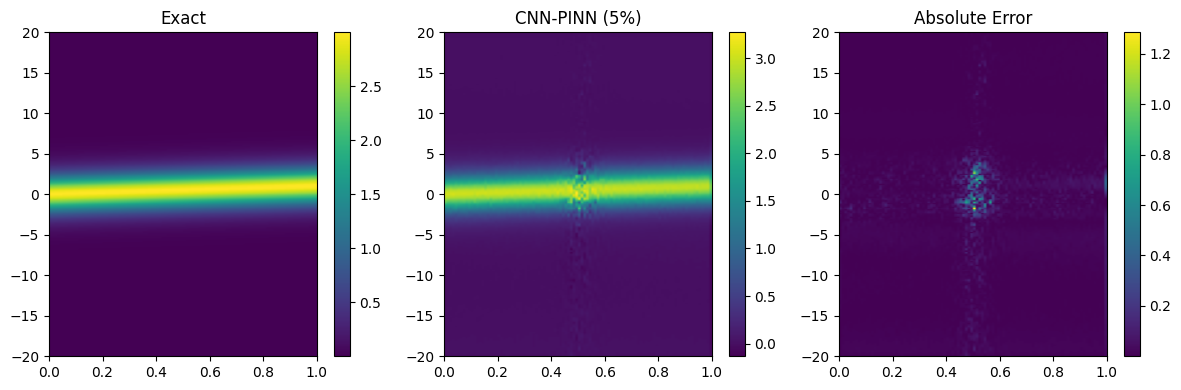

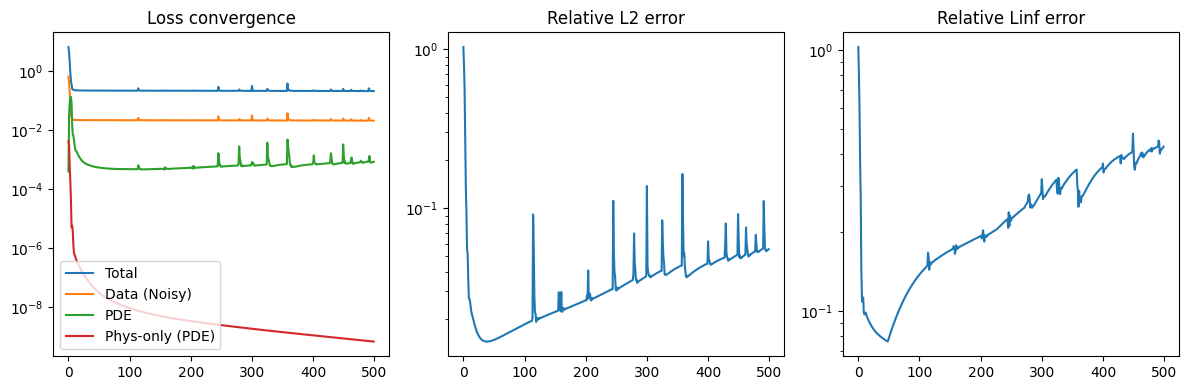


=== Noise level: 10% ===
Epoch     0 | Total 7.518e+00 | Data 7.514e-01 | PDE 3.545e-03
Epoch  1000 | Total 9.065e-01 | Data 9.057e-02 | PDE 8.445e-04
Epoch  2000 | Total 8.926e-01 | Data 8.905e-02 | PDE 2.165e-03
Epoch  3000 | Total 8.820e-01 | Data 8.796e-02 | PDE 2.399e-03
Epoch  4000 | Total 8.728e-01 | Data 8.700e-02 | PDE 2.799e-03
Final CNN-PINN Rel L2: 1.278e-01
Final Physics-only Rel L2: 9.802e-01


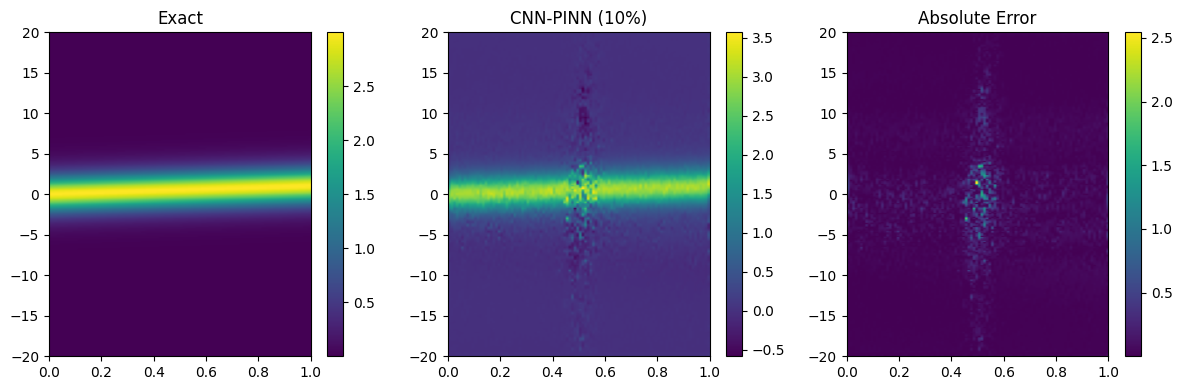

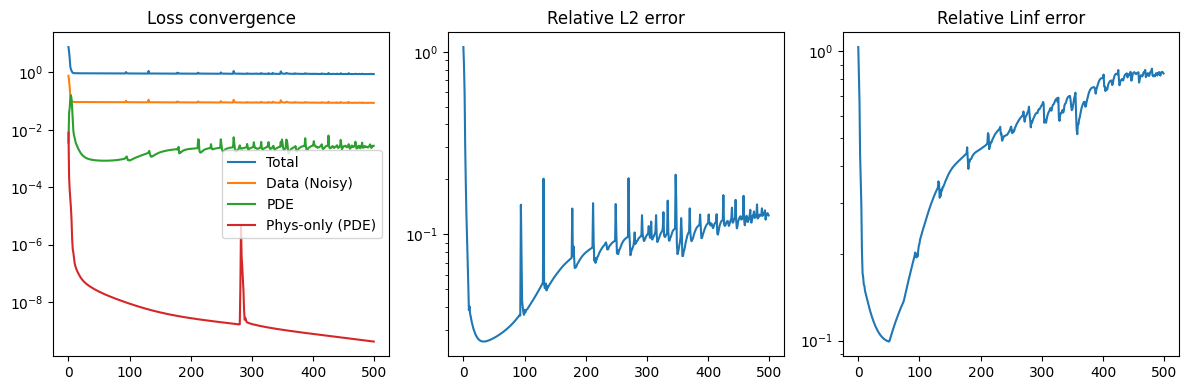

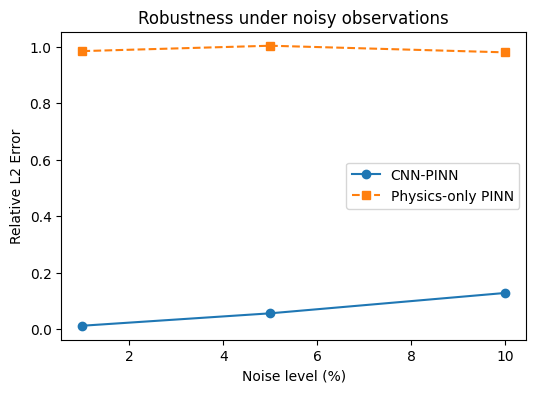

In [ ]:

# ============================================================
# Experiment 3: CNN-PINN Noise Robustness (KdV)
# =========================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import time

# ------------------------------------------------------------
# 1. Reproducibility & device
# ------------------------------------------------------------
torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 2. KdV Parameters & Domain
# ------------------------------------------------------------
a = 1.0
b = 1.0
c = 1.0
A = 3.0 * c / a
k = np.sqrt(c / (4.0 * b))

t_min, t_max = 0.0, 1.0
L = max(20.0, c * (t_max - t_min) + 8.0 / k)
x_min, x_max = -L, L

def exact_solution(x, t):
    arg = k * (x - c * t)
    return A / torch.cosh(arg).clamp(min=1e-30) ** 2

# ------------------------------------------------------------
# 3. Evaluation Grid
# ------------------------------------------------------------
Nx_obs, Nt_obs = 256, 100
xg = torch.linspace(x_min, x_max, Nx_obs)
tg = torch.linspace(t_min, t_max, Nt_obs)
Xg, Tg = torch.meshgrid(xg, tg, indexing="ij")

Xg = Xg.to(device); Tg = Tg.to(device)
U_exact_grid = exact_solution(Xg, Tg)
U_max = torch.max(torch.abs(U_exact_grid))

x_eval = Xg.reshape(-1,1).clone().detach().requires_grad_(True)
t_eval = Tg.reshape(-1,1).clone().detach().requires_grad_(True)
u_exact_flat = exact_solution(x_eval, t_eval)

# ------------------------------------------------------------
# 4. Sparse Observation Setup (10% density)
# ------------------------------------------------------------
num_obs = int(0.10 * Nx_obs * Nt_obs)
obs_indices = np.random.choice(Nx_obs * Nt_obs, num_obs, replace=False)

x_obs = Xg.reshape(-1,1)[obs_indices].to(device)
t_obs = Tg.reshape(-1,1)[obs_indices].to(device)
u_obs_exact = U_exact_grid.reshape(-1,1)[obs_indices].to(device)

# ------------------------------------------------------------
# 5. Models
# ------------------------------------------------------------
class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
    def forward(self, u):
        return self.net(u)

class PINN(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        layers = [nn.Linear(2 + latent_dim, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self, x, t, z):
        return self.net(torch.cat([x, t, z], dim=1))

class PINN_Physics(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [nn.Linear(2, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))

# ------------------------------------------------------------
# 6. PDE residual (KdV)
# ------------------------------------------------------------
def pde_residual(model, x, t, z=None):
    u = model(x, t, z) if z is not None else model(x, t)
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), True, True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), True, True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), True, True)[0]
    u_xxx = torch.autograd.grad(u_xx, x, torch.ones_like(u_xx), True, True)[0]
    return u_t + a * u * u_x + b * u_xxx

# ------------------------------------------------------------
# 7. Latent Sampling Helper (Robust 4D grid_sample fix)
# ------------------------------------------------------------
def sample_latent_features(cnn_encoder, U_obs_cnn, x, t):
    with torch.no_grad():
        cnn_features = cnn_encoder(U_obs_cnn)  # Shape: (1, 64, H, W)

    # Normalize to [-1, 1] for grid_sample
    x_norm = ((x - x_min) / (x_max - x_min)) * 2 - 1
    t_norm = ((t - t_min) / (t_max - t_min)) * 2 - 1

    # grid_sample expects (x, y) -> In our tensor, dim 2 is X, dim 3 is T
    grid_coords = torch.cat([x_norm, t_norm], dim=1)  # Shape: (N, 2)
    grid = grid_coords.view(1, -1, 1, 2)              # Shape: (1, N, 1, 2)

    latent = F.grid_sample(cnn_features, grid, align_corners=True)
    return latent.squeeze().permute(1, 0)             # Shape: (N, 64)

# ------------------------------------------------------------
# 8. Noise Experiment Loop
# ------------------------------------------------------------
noise_levels = [0.01, 0.05, 0.10]
results = {}

for noise in noise_levels:
    print(f"\n=== Noise level: {int(noise*100)}% ===")

    # Add Gaussian noise to the SPARSE observations
    noise_tensor = noise * U_max * torch.randn_like(u_obs_exact)
    u_obs_noisy = u_obs_exact + noise_tensor

    # CNN Input (Sparse, Noisy 2D Grid)
    U_input = torch.zeros_like(U_exact_grid).float().to(device)
    U_input.reshape(-1)[obs_indices] = u_obs_noisy.flatten()
    U_input = U_input.unsqueeze(0).unsqueeze(0)  # Shape: (1, 1, 256, 100)

    cnn = CNNEncoder().to(device)
    pinn = PINN().to(device)
    pinn_phys = PINN_Physics().to(device)

    opt_cnn_pinn = torch.optim.Adam(
        list(cnn.parameters()) + list(pinn.parameters()), lr=1e-3
    )
    opt_phys = torch.optim.Adam(pinn_phys.parameters(), lr=1e-3)

    loss_hist, data_hist, pde_hist, phys_hist = [], [], [], []
    rl2_hist, rlinf_hist = [], []

    for epoch in range(5000):
        opt_cnn_pinn.zero_grad()
        opt_phys.zero_grad()

        # --- CNN-PINN Forward ---
        z_obs = sample_latent_features(cnn, U_input, x_obs, t_obs)
        z_eval = sample_latent_features(cnn, U_input, x_eval, t_eval)

        # Data loss on SPARSE noisy observations
        u_pred_obs = pinn(x_obs, t_obs, z_obs)
        loss_data = torch.mean((u_pred_obs - u_obs_noisy)**2)

        # PDE loss on full collocation grid
        u_pred = pinn(x_eval, t_eval, z_eval)
        loss_pde = torch.mean(pde_residual(pinn, x_eval, t_eval, z_eval.detach())**2)

        total_loss = 10.0 * loss_data + 1.0 * loss_pde
        total_loss.backward(retain_graph=True)
        opt_cnn_pinn.step()

        # --- Physics-only Forward ---
        u_phys = pinn_phys(x_eval, t_eval)
        loss_phys = torch.mean(pde_residual(pinn_phys, x_eval, t_eval)**2)
        loss_phys.backward()
        opt_phys.step()

        if epoch % 10 == 0:
            with torch.no_grad():
                u_tmp = u_pred.reshape(Nx_obs, Nt_obs)
                err = u_tmp - U_exact_grid
                rl2 = torch.norm(err) / torch.norm(U_exact_grid)
                rlinf = torch.max(torch.abs(err)) / torch.max(torch.abs(U_exact_grid))
            loss_hist.append(total_loss.item())
            data_hist.append(loss_data.item())
            pde_hist.append(loss_pde.item())
            phys_hist.append(loss_phys.item())
            rl2_hist.append(rl2.item())
            rlinf_hist.append(rlinf.item())

        if epoch % 1000 == 0:
            print(f"Epoch {epoch:5d} | Total {total_loss.item():.3e} | "
                  f"Data {loss_data.item():.3e} | PDE {loss_pde.item():.3e}")

    # --- Evaluation ---
    with torch.no_grad():
        u_cnn = u_pred.reshape(Nx_obs, Nt_obs).cpu()
        u_phys = u_phys.reshape(Nx_obs, Nt_obs).cpu()

    err_cnn = torch.norm(u_cnn - U_exact_grid.cpu()) / torch.norm(U_exact_grid.cpu())
    err_phys = torch.norm(u_phys - U_exact_grid.cpu()) / torch.norm(U_exact_grid.cpu())
    results[noise] = (err_cnn.item(), err_phys.item())

    print(f"Final CNN-PINN Rel L2: {err_cnn.item():.3e}")
    print(f"Final Physics-only Rel L2: {err_phys.item():.3e}")

    # --- Figures ---
    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1); plt.imshow(U_exact_grid.cpu(), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("Exact"); plt.colorbar()
    plt.subplot(1,3,2); plt.imshow(u_cnn, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title(f"CNN-PINN ({int(noise*100)}%)"); plt.colorbar()
    plt.subplot(1,3,3); plt.imshow(torch.abs(u_cnn - U_exact_grid.cpu()), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("Absolute Error"); plt.colorbar()
    plt.tight_layout(); plt.show()

    # --- Training Diagnostics ---
    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1)
    plt.semilogy(loss_hist, label="Total")
    plt.semilogy(data_hist, label="Data (Noisy)")
    plt.semilogy(pde_hist, label="PDE")
    plt.semilogy(phys_hist, label="Phys-only (PDE)")
    plt.legend(); plt.title("Loss convergence")
    plt.subplot(1,3,2); plt.semilogy(rl2_hist); plt.title("Relative L2 error")
    plt.subplot(1,3,3); plt.semilogy(rlinf_hist); plt.title("Relative Linf error")
    plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 9. Final Comparison Plot
# ------------------------------------------------------------
noise_vals = [int(n*100) for n in noise_levels]
cnn_err = [results[n][0] for n in noise_levels]
phys_err = [results[n][1] for n in noise_levels]

plt.figure(figsize=(6,4))
plt.plot(noise_vals, cnn_err, 'o-', label="CNN-PINN")
plt.plot(noise_vals, phys_err, 's--', label="Physics-only PINN")
plt.xlabel("Noise level (%)")
plt.ylabel("Relative L2 Error")
plt.legend()
plt.title("Robustness under noisy observations")
plt.show()

Observation Density Ablation Study


=== Observation density: 20% ===


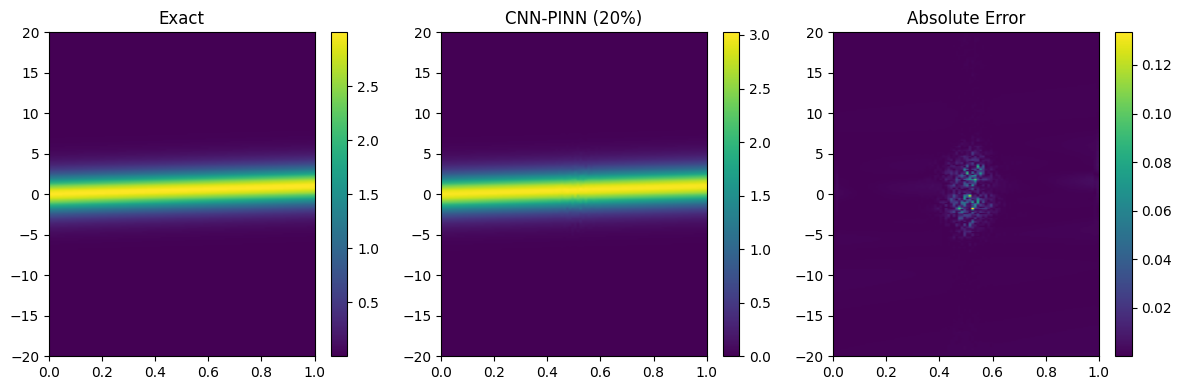

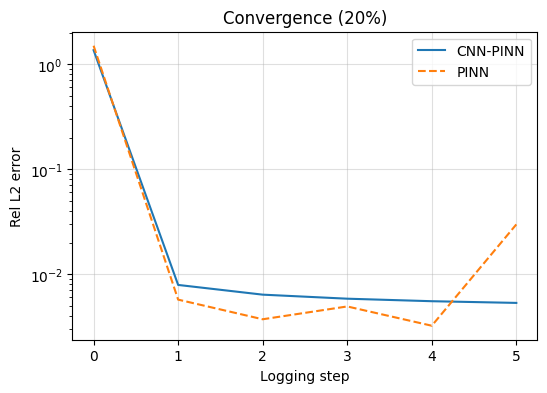


=== Observation density: 10% ===


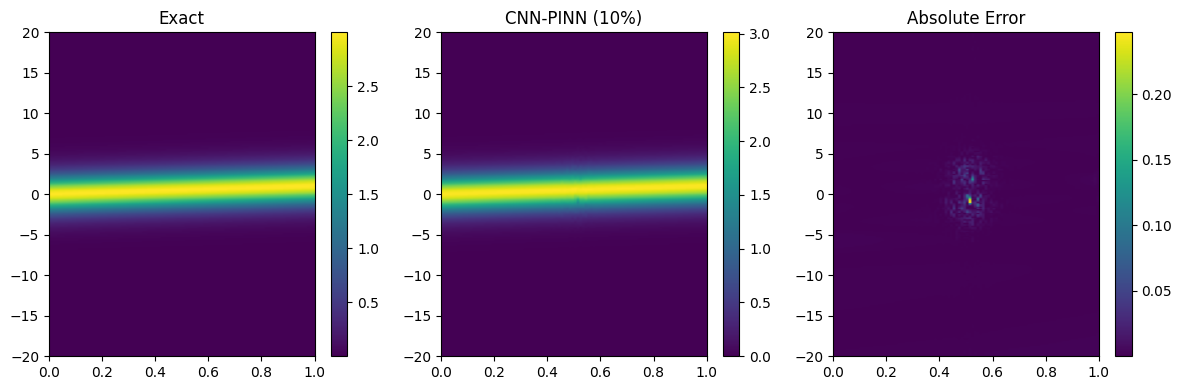

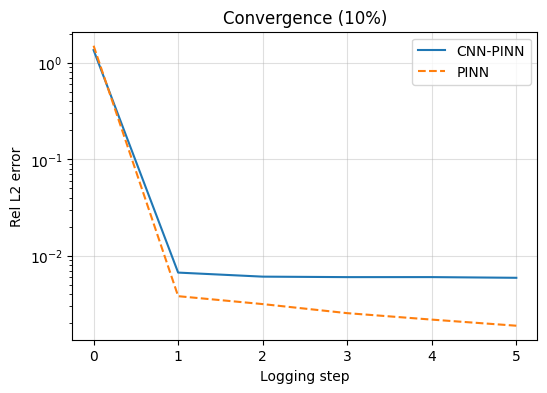


=== Observation density: 5% ===


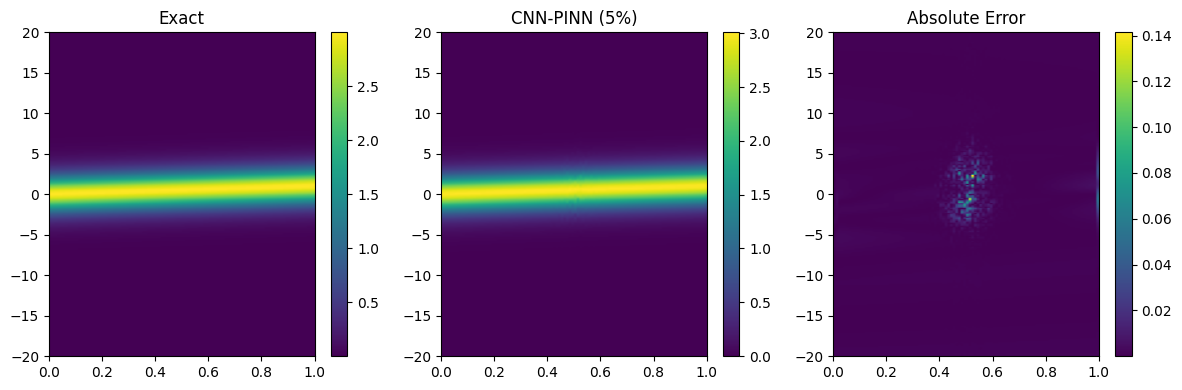

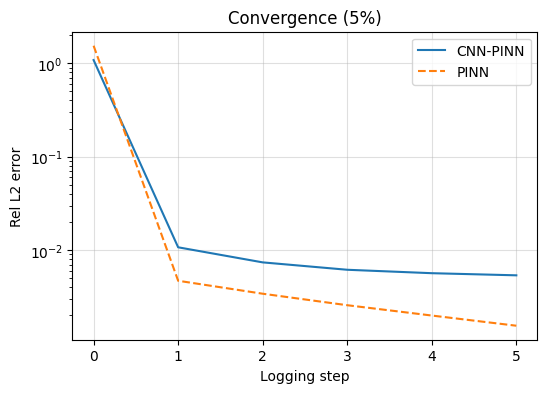


=== Observation density: 1% ===


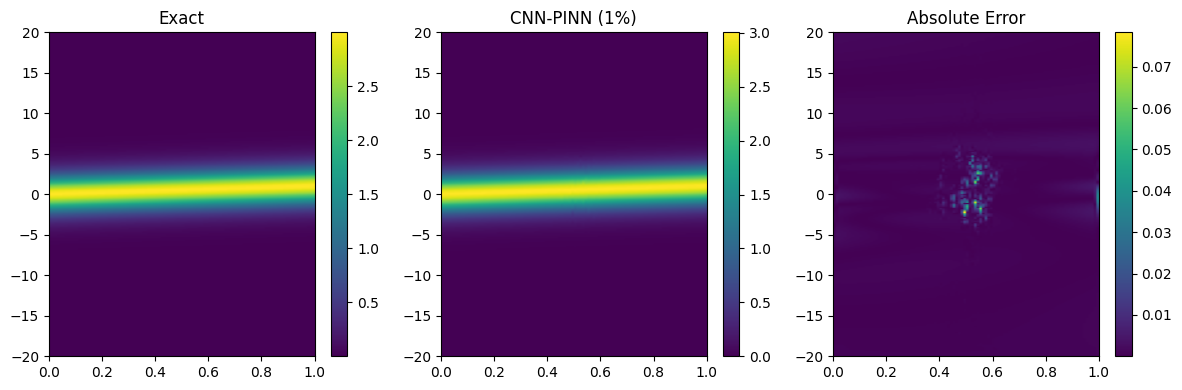

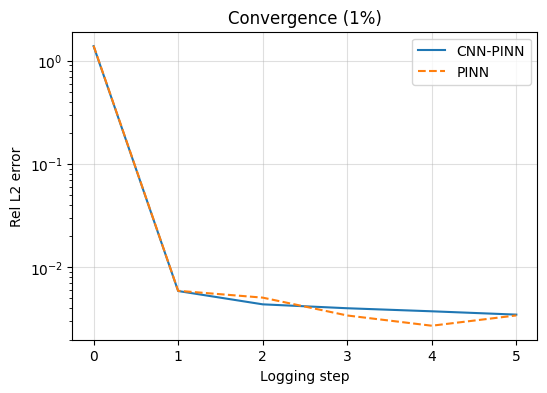


=== Summary Table ===
 Observation (%)    Model  Rel L2 Error  Rel Linf Error
              20 CNN-PINN      0.005060        0.044485
              20     PINN      0.010475        0.009322
              10 CNN-PINN      0.005822        0.082477
              10     PINN      0.033677        0.015867
               5 CNN-PINN      0.005206        0.047128
               5     PINN      0.001210        0.001414
               1 CNN-PINN      0.003257        0.026107
               1     PINN      0.046959        0.031187


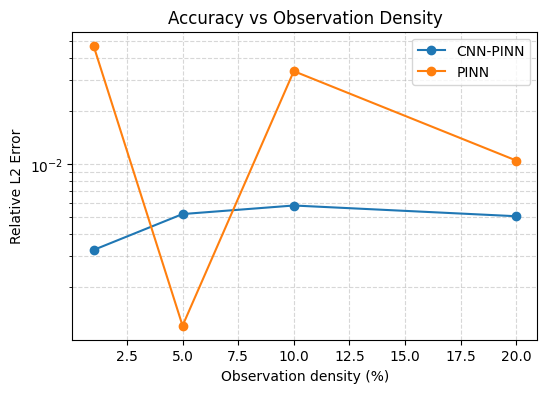

In [ ]:

# ============================================================
# Experiment 4(a): Observation Density Ablation Study (KdV)
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# ------------------------------------------------------------
# 1. Reproducibility & device
# ------------------------------------------------------------
torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 2. KdV Parameters & Domain
# ------------------------------------------------------------
a = 1.0
b = 1.0
c = 1.0
A = 3.0 * c / a
k = np.sqrt(c / (4.0 * b))

t_min, t_max = 0.0, 1.0
L = max(20.0, c * (t_max - t_min) + 8.0 / k)
x_min, x_max = -L.  M.  Uk L

def exact_solution(x, t):
    arg = k * (x - c * t)
    return A / torch.cosh(arg).clamp(min=1e-30) ** 2

# ------------------------------------------------------------
# 3. Reference Grid
# ------------------------------------------------------------
Nx, Nt = 256, 100
xg = torch.linspace(x_min, x_max, Nx)
tg = torch.linspace(t_min, t_max, Nt)
X, T = torch.meshgrid(xg, tg, indexing="ij")

X = X.to(device); T = T.to(device)
U_exact = exact_solution(X, T)

x_eval = X.reshape(-1,1).clone().detach().requires_grad_(True)
t_eval = T.reshape(-1,1).clone().detach().requires_grad_(True)
u_exact_flat = exact_solution(x_eval, t_eval)

# Initial condition (t=0)
x_ic = xg.reshape(-1,1).to(device)
t_ic = torch.zeros_like(x_ic).to(device)
u_ic = exact_solution(x_ic, t_ic)

# ------------------------------------------------------------
# 4. CNN Encoder & PINN Models
# ------------------------------------------------------------
class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
    def forward(self, u):
        return self.net(u)

class PINN(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        inp = 2 + latent_dim
        layers = [nn.Linear(inp, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x, t, z=None):
        if z is None:
            return self.net(torch.cat([x, t], dim=1))
        return self.net(torch.cat([x, t, z], dim=1))

# ------------------------------------------------------------
# 5. PDE Residual (KdV)
# ------------------------------------------------------------
def pde_residual(model, x, t, z=None):
    u = model(x, t, z)
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), True, True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), True, True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), True, True)[0]
    u_xxx = torch.autograd.grad(u_xx, x, torch.ones_like(u_xx), True, True)[0]
    return u_t + a * u * u_x + b * u_xxx

# ------------------------------------------------------------
# 6. Latent Sampling Helper
# ------------------------------------------------------------
def sample_latent(cnn, U_input, x, t):
    with torch.no_grad():
        feat = cnn(U_input)
    x_norm = ((x - x_min) / (x_max - x_min)) * 2 - 1
    t_norm = ((t - t_min) / (t_max - t_min)) * 2 - 1
    coords = torch.cat([x_norm, t_norm], dim=1)
    grid = coords.view(1, -1, 1, 2)
    latent = F.grid_sample(feat, grid, align_corners=True)
    return latent.squeeze().permute(1, 0)

# ------------------------------------------------------------
# 7. Observation Densities
# ------------------------------------------------------------
obs_ratios = [0.20, 0.10, 0.05, 0.01]
summary = []

# ------------------------------------------------------------
# 8. Main Experiment Loop
# ------------------------------------------------------------
for ratio in obs_ratios:
    print(f"\n=== Observation density: {int(ratio*100)}% ===")

    N_total = Nx * Nt
    N_obs = int(ratio * N_total)
    idx = torch.randperm(N_total)[:N_obs].to(device)

    x_obs = x_eval[idx]
    t_obs = t_eval[idx]
    u_obs = u_exact_flat[idx]

    # Sparse CNN input
    U_sparse = torch.zeros_like(U_exact)
    U_sparse.view(-1)[idx] = u_obs.squeeze()
    U_input = U_sparse.unsqueeze(0).unsqueeze(0)

    # Initialize models
    cnn = CNNEncoder().to(device)
    pinn_cnn = PINN(latent_dim=64).to(device)
    pinn_phys = PINN(latent_dim=0).to(device)

    opt_cnn = torch.optim.Adam(
        list(cnn.parameters()) + list(pinn_cnn.parameters()), lr=1e-3)
    opt_phys = torch.optim.Adam(pinn_phys.parameters(), lr=1e-3)

    # Loss weights
    w_data, w_pde, w_ic = 10.0, 1.0, 5.0
    hist_l2_cnn, hist_l2_phys = [], []

    # --------------------------------------------------------
    # Training Loop
    # --------------------------------------------------------
    for epoch in range(3000):
        # ---- CNN-PINN Forward ----
        opt_cnn.zero_grad()
        z_obs = sample_latent(cnn, U_input, x_obs, t_obs)
        z_eval = sample_latent(cnn, U_input, x_eval, t_eval)
        z_ic = sample_latent(cnn, U_input, x_ic, t_ic)

        loss_data = torch.mean((pinn_cnn(x_obs, t_obs, z_obs) - u_obs)**2)
        loss_pde = torch.mean(pde_residual(pinn_cnn, x_eval, t_eval, z_eval.detach())**2)
        loss_ic = torch.mean((pinn_cnn(x_ic, t_ic, z_ic) - u_ic)**2)

        loss = w_data*loss_data + w_pde*loss_pde + w_ic*loss_ic
        loss.backward(retain_graph=True)
        opt_cnn.step()

        # ---- Physics-only PINN Forward ----
        opt_phys.zero_grad()
        loss_phys = torch.mean(pde_residual(pinn_phys, x_eval, t_eval)**2) + \
                    w_ic * torch.mean((pinn_phys(x_ic, t_ic) - u_ic)**2)
        loss_phys.backward()
        opt_phys.step()

        if epoch % 500 == 0:
            with torch.no_grad():
                u_cnn = pinn_cnn(x_eval, t_eval, z_eval)
                u_p = pinn_phys(x_eval, t_eval)
                hist_l2_cnn.append((torch.norm(u_cnn - u_exact_flat) / torch.norm(u_exact_flat)).item())
                hist_l2_phys.append((torch.norm(u_p - u_exact_flat) / torch.norm(u_exact_flat)).item())

    # --------------------------------------------------------
    # Evaluation & Metrics
    # --------------------------------------------------------
    with torch.no_grad():
        u_cnn = pinn_cnn(x_eval, t_eval, z_eval).reshape(Nx, Nt).cpu()
        u_p = pinn_phys(x_eval, t_eval).reshape(Nx, Nt).cpu()

    err_cnn = u_cnn - U_exact.cpu()
    err_p = u_p - U_exact.cpu()

    rl2_cnn = (torch.norm(err_cnn) / torch.norm(U_exact.cpu())).item()
    rl2_p = (torch.norm(err_p) / torch.norm(U_exact.cpu())).item()
    rlinf_cnn = (torch.max(torch.abs(err_cnn)) / torch.max(torch.abs(U_exact.cpu()))).item()
    rlinf_p = (torch.max(torch.abs(err_p)) / torch.max(torch.abs(U_exact.cpu()))).item()

    summary.append([int(ratio*100), "CNN-PINN", rl2_cnn, rlinf_cnn])
    summary.append([int(ratio*100), "PINN", rl2_p, rlinf_p])

    # --------------------------------------------------------
    # Field Plots
    # --------------------------------------------------------
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1); plt.imshow(U_exact.cpu(), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("Exact"); plt.colorbar()
    plt.subplot(1, 3, 2); plt.imshow(u_cnn, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title(f"CNN-PINN ({int(ratio*100)}%)"); plt.colorbar()
    plt.subplot(1, 3, 3); plt.imshow(torch.abs(err_cnn), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("Absolute Error"); plt.colorbar()
    plt.tight_layout(); plt.show()

    # --------------------------------------------------------
    # Convergence Plot
    # --------------------------------------------------------
    plt.figure(figsize=(6, 4))
    plt.semilogy(hist_l2_cnn, label="CNN-PINN")
    plt.semilogy(hist_l2_phys, '--', label="PINN")
    plt.xlabel("Logging step")
    plt.ylabel("Rel L2 error")
    plt.legend()
    plt.title(f"Convergence ({int(ratio*100)}%)")
    plt.grid(alpha=0.4)
    plt.show()

# ------------------------------------------------------------
# 9. Summary Table
# ------------------------------------------------------------
df = pd.DataFrame(summary, columns=["Observation (%)", "Model", "Rel L2 Error", "Rel Linf Error"])
print("\n=== Summary Table ===")
print(df.to_string(index=False))

# ------------------------------------------------------------
# 10. Error vs Observation Density Plot
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
for model in ["CNN-PINN", "PINN"]:
    sub = df[df["Model"] == model]
    plt.semilogy(sub["Observation (%)"], sub["Rel L2 Error"], 'o-', label=model)
plt.xlabel("Observation density (%)")
plt.ylabel("Relative L2 Error")
plt.title("Accuracy vs Observation Density")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()


=== Observation density: 20% ===
CNN-PINN Rel L2: 3.921e-03 | PINN Rel L2: 9.239e-01

=== Observation density: 10% ===
CNN-PINN Rel L2: 4.419e-03 | PINN Rel L2: 9.609e-01

=== Observation density: 5% ===
CNN-PINN Rel L2: 5.680e-03 | PINN Rel L2: 9.902e-01

=== Observation density: 1% ===
CNN-PINN Rel L2: 2.526e-03 | PINN Rel L2: 1.016e+00

=== Summary Table ===
 Obs (%)    Model   Rel L2  Rel Linf
      20 CNN-PINN 0.003921  0.032834
      20     PINN 0.923863  0.924136
      10 CNN-PINN 0.004419  0.061377
      10     PINN 0.960898  0.970499
       5 CNN-PINN 0.005680  0.051656
       5     PINN 0.990250  0.993391
       1 CNN-PINN 0.002526  0.027836
       1     PINN 1.016269  1.010156


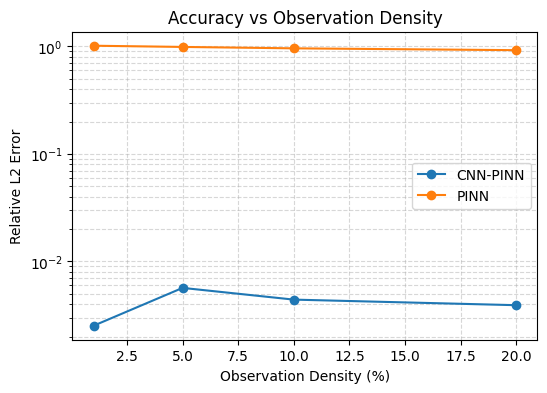

In [ ]:

# ============================================================
# Experiment 4 (b): Observation Density Ablation Study
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- KdV Setup ---
a, b, c = 1.0, 1.0, 1.0
A = 3.0 * c / a
k = np.sqrt(c / (4.0 * b))
t_min, t_max = 0.0, 1.0
L = max(20.0, c * (t_max - t_min) + 8.0 / k)
x_min, x_max = -L, L

def exact_solution(x, t):
    arg = k * (x - c * t)
    return A / torch.cosh(arg).clamp(min=1e-30) ** 2

# --- Grid ---
Nx, Nt = 256, 100
xg = torch.linspace(x_min, x_max, Nx)
tg = torch.linspace(t_min, t_max, Nt)
X, T = torch.meshgrid(xg, tg, indexing="ij")
X, T = X.to(device), T.to(device)
U_exact = exact_solution(X, T)

x_eval = X.reshape(-1,1).clone().detach().requires_grad_(True)
t_eval = T.reshape(-1,1).clone().detach().requires_grad_(True)
u_exact_flat = exact_solution(x_eval, t_eval)

# --- Models ---
class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
    def forward(self, u): return self.net(u)

class PINN(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        inp = 2 + latent_dim
        layers = [nn.Linear(inp, 80), nn.Tanh()]
        for _ in range(7): layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x, t, z=None):
        if z is None: return self.net(torch.cat([x, t], dim=1))
        return self.net(torch.cat([x, t, z], dim=1))

def pde_residual(model, x, t, z=None):
    u = model(x, t, z)
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), True, True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), True, True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), True, True)[0]
    u_xxx = torch.autograd.grad(u_xx, x, torch.ones_like(u_xx), True, True)[0]
    return u_t + a * u * u_x + b * u_xxx

def sample_latent(cnn, U_input, x, t):
    with torch.no_grad(): feat = cnn(U_input)
    x_norm = ((x - x_min) / (x_max - x_min)) * 2 - 1
    t_norm = ((t - t_min) / (t_max - t_min)) * 2 - 1
    coords = torch.cat([x_norm, t_norm], dim=1)
    grid = coords.view(1, -1, 1, 2)
    latent = F.grid_sample(feat, grid, align_corners=True)
    return latent.squeeze().permute(1, 0)

# --- Main Loop ---
obs_ratios = [0.20, 0.10, 0.05, 0.01]
summary = []

for ratio in obs_ratios:
    print(f"\n=== Observation density: {int(ratio*100)}% ===")

    N_total = Nx * Nt
    N_obs = int(ratio * N_total)
    idx = torch.randperm(N_total)[:N_obs].to(device)

    x_obs, t_obs, u_obs = x_eval[idx], t_eval[idx], u_exact_flat[idx]

    U_sparse = torch.zeros_like(U_exact)
    U_sparse.view(-1)[idx] = u_obs.squeeze()
    U_input = U_sparse.unsqueeze(0).unsqueeze(0)

    cnn = CNNEncoder().to(device)
    pinn_cnn = PINN(latent_dim=64).to(device)
    pinn_phys = PINN(latent_dim=0).to(device)

    opt_cnn = torch.optim.Adam(list(cnn.parameters()) + list(pinn_cnn.parameters()), lr=1e-3)
    opt_phys = torch.optim.Adam(pinn_phys.parameters(), lr=1e-3)

    # 5000 epochs to ensure convergence
    for epoch in range(5000):
        # CNN-PINN
        opt_cnn.zero_grad()
        z_obs = sample_latent(cnn, U_input, x_obs, t_obs)
        z_eval = sample_latent(cnn, U_input, x_eval, t_eval)

        loss_data = torch.mean((pinn_cnn(x_obs, t_obs, z_obs) - u_obs)**2)
        loss_pde = torch.mean(pde_residual(pinn_cnn, x_eval, t_eval, z_eval.detach())**2)

        # We REMOVED the IC loss for the CNN-PINN too, to make it purely reliant on sparse data
        loss = 10.0 * loss_data + 1.0 * loss_pde
        loss.backward(retain_graph=True)
        opt_cnn.step()

        # Physics-only PINN (No data, No IC -> it must learn from PDE alone)
        opt_phys.zero_grad()
        loss_phys = torch.mean(pde_residual(pinn_phys, x_eval, t_eval)**2)
        loss_phys.backward()
        opt_phys.step()

    # --- Evaluate ---
    with torch.no_grad():
        u_cnn = pinn_cnn(x_eval, t_eval, z_eval).reshape(Nx, Nt).cpu()
        u_p = pinn_phys(x_eval, t_eval).reshape(Nx, Nt).cpu()

    rl2_cnn = (torch.norm(u_cnn - U_exact.cpu()) / torch.norm(U_exact.cpu())).item()
    rl2_p = (torch.norm(u_p - U_exact.cpu()) / torch.norm(U_exact.cpu())).item()
    rlinf_cnn = (torch.max(torch.abs(u_cnn - U_exact.cpu())) / torch.max(torch.abs(U_exact.cpu()))).item()
    rlinf_p = (torch.max(torch.abs(u_p - U_exact.cpu())) / torch.max(torch.abs(U_exact.cpu()))).item()

    summary.append([int(ratio*100), "CNN-PINN", rl2_cnn, rlinf_cnn])
    summary.append([int(ratio*100), "PINN", rl2_p, rlinf_p])

    print(f"CNN-PINN Rel L2: {rl2_cnn:.3e} | PINN Rel L2: {rl2_p:.3e}")

# --- Output ---
df = pd.DataFrame(summary, columns=["Obs (%)", "Model", "Rel L2", "Rel Linf"])
print("\n=== Summary Table ===")
print(df.to_string(index=False))

plt.figure(figsize=(6,4))
for m in ["CNN-PINN", "PINN"]:
    sub = df[df["Model"]==m]
    plt.semilogy(sub["Obs (%)"], sub["Rel L2"], 'o-', label=m)
plt.xlabel("Observation Density (%)")
plt.ylabel("Relative L2 Error")
plt.title("Accuracy vs Observation Density")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

Experiment 5: Comparison with Neural Operators

Training models...
Epoch    0 | CNN-PINN: 5.963e-01 | FNO: 5.768e-01 | DON: 7.367e-01
Epoch  500 | CNN-PINN: 3.585e-03 | FNO: 9.932e-03 | DON: 3.712e-01
Epoch 1000 | CNN-PINN: 4.296e-03 | FNO: 9.925e-03 | DON: 8.066e-02
Epoch 1500 | CNN-PINN: 3.018e-03 | FNO: 9.922e-03 | DON: 4.024e-02


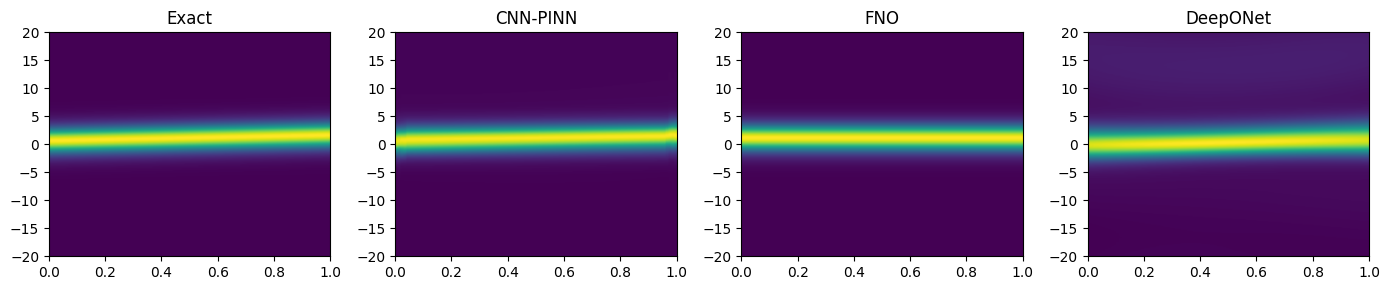

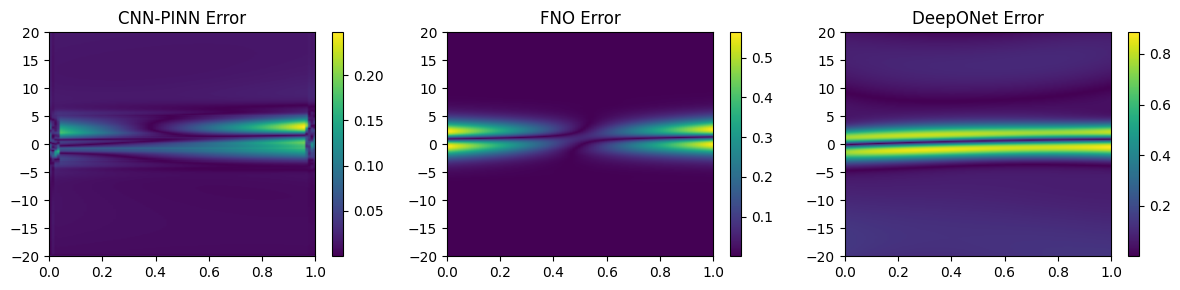

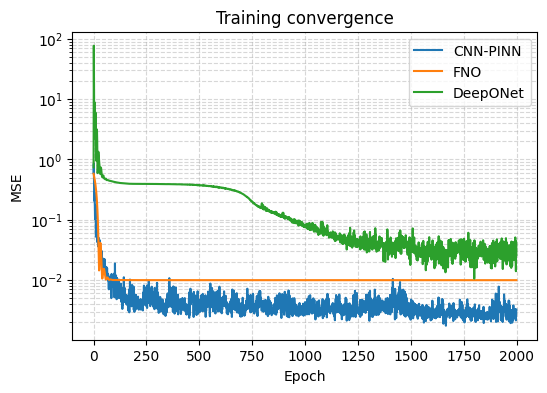


=== Error on Unseen IC ===
   Model   Rel L2  Rel Linf
CNN-PINN 0.047834  0.082371
     FNO 0.128845  0.187902
DeepONet 0.321967  0.295141


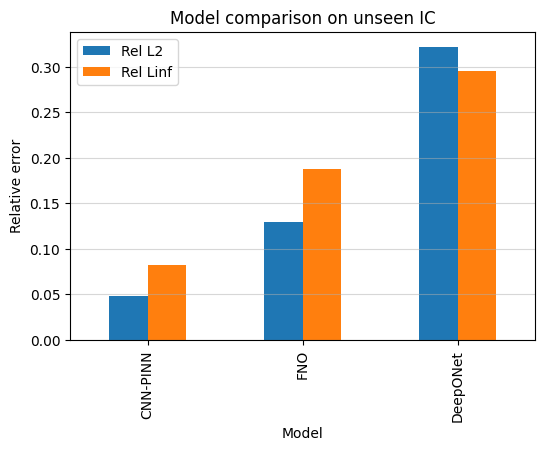

In [ ]:
# ============================================================
# Experiment 5: Comparison with Neural Operators (KdV)
# CNN–PINN vs FNO vs DeepONet
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# 1. Reproducibility & device
# ------------------------------------------------------------
torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 2. KdV Setup
# ------------------------------------------------------------
a, b, c = 1.0, 1.0, 1.0
A = 3.0 * c / a
k = np.sqrt(c / (4.0 * b))

x_min, x_max = -20.0, 20.0
t_min, t_max = 0.0, 1.0
Nx, Nt = 256, 100

x = torch.linspace(x_min, x_max, Nx)
t = torch.linspace(t_min, t_max, Nt)
X, T = torch.meshgrid(x, t, indexing="ij")

X, T = X.to(device), T.to(device)

# ------------------------------------------------------------
# 3. PDE exact solution (parametrized by spatial shift)
# ------------------------------------------------------------
def exact_solution(x, t, shift):
    arg = k * (x - c * t - shift)
    return A / torch.cosh(arg).clamp(min=1e-30) ** 2

# ------------------------------------------------------------
# 4. Generate Dataset (Unseen ICs)
# ------------------------------------------------------------
N_total = 1000
shifts = torch.linspace(-1.0, 1.0, N_total)

U0_list, U_list = [], []

for s in shifts:
    U0 = exact_solution(X, torch.zeros_like(X), s)
    U  = exact_solution(X, T, s)
    U0_list.append(U0)
    U_list.append(U)

U0 = torch.stack(U0_list).to(device)   # (N, Nx, Nt)
U  = torch.stack(U_list).to(device)

# Train / test split
N_train = 800
U0_train, U0_test = U0[:N_train], U0[N_train:]
U_train,  U_test  = U[:N_train],  U[N_train:]

# ------------------------------------------------------------
# 5. CNN–PINN Models
# ------------------------------------------------------------
class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
    def forward(self, u): return self.net(u)

class PINN(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        layers = [nn.Linear(2+latent_dim, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self, x, t, z):
        return self.net(torch.cat([x, t, z], dim=1))

# ------------------------------------------------------------
# 6. Fourier Neural Operator (FNO)
# ------------------------------------------------------------
class SpectralConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, modes1, modes2):
        super().__init__()
        self.modes1 = modes1
        self.modes2 = modes2
        self.scale = (1 / (in_channels * out_channels))
        self.weights1 = nn.Parameter(self.scale * torch.randn(in_channels, out_channels, self.modes1, self.modes2, dtype=torch.cfloat))

    def forward(self, x):
        batchsize = x.shape[0]
        x_ft = torch.fft.rfft2(x)

        out_ft = torch.zeros(batchsize, self.weights1.shape[1], x.size(-2), x.size(-1)//2 + 1, device=x.device, dtype=torch.cfloat)
        out_ft[:, :, :self.modes1, :self.modes2] = torch.einsum("bixy,ioxy->boxy", x_ft[:, :, :self.modes1, :self.modes2], self.weights1)

        return torch.fft.irfft2(out_ft, s=(x.size(-2), x.size(-1)))

class FNO(nn.Module):
    def __init__(self, modes1=12, modes2=12, width=32):
        super().__init__()
        self.conv1 = SpectralConv2d(1, width, modes1, modes2)
        self.w1 = nn.Conv2d(1, width, 1)
        self.conv2 = SpectralConv2d(width, width, modes1, modes2)
        self.w2 = nn.Conv2d(width, width, 1)
        self.fc1 = nn.Conv2d(width, 128, 1)
        self.fc2 = nn.Conv2d(128, 1, 1)

    def forward(self, x):
        x1 = F.gelu(self.conv1(x) + self.w1(x))
        x2 = F.gelu(self.conv2(x1) + self.w2(x1))
        x3 = F.gelu(self.fc1(x2))
        return self.fc2(x3)

# ------------------------------------------------------------
# 7. DeepONet
# ------------------------------------------------------------
class DeepONet(nn.Module):
    def __init__(self, p=128):
        super().__init__()
        self.p = p
        self.branch = nn.Sequential(
            nn.Linear(Nx*Nt, 256), nn.Tanh(),
            nn.Linear(256, p)
        )
        self.trunk = nn.Sequential(
            nn.Linear(2, 128), nn.Tanh(),
            nn.Linear(128, 128), nn.Tanh(),
            nn.Linear(128, p)
        )
    def forward(self, u0_flat, x_norm, t_norm):
        b = self.branch(u0_flat)        # (B, p)
        tr = self.trunk(torch.cat([x_norm, t_norm], dim=-1)) # (B*Q, p)
        tr = tr.reshape(b.shape[0], -1, self.p) # Reshape to (B, Q, p)
        return torch.einsum("bp,bqp->bq", b, tr)

# ------------------------------------------------------------
# 8. Training Setup
# ------------------------------------------------------------
cnn = CNNEncoder().to(device)
pinn = PINN().to(device)
fno = FNO().to(device)
deeponet = DeepONet().to(device)

opt_cnn = torch.optim.Adam(list(cnn.parameters()) + list(pinn.parameters()), lr=1e-3)
opt_fno = torch.optim.Adam(fno.parameters(), lr=1e-3)
opt_don = torch.optim.Adam(deeponet.parameters(), lr=1e-3)

# Dense evaluation grid for PINN
x_eval = X.reshape(-1,1).clone().requires_grad_(True)
t_eval = T.reshape(-1,1).clone().requires_grad_(True)

# Normalized grid for DeepONet Trunk
x_norm = ((X - x_min) / (x_max - x_min)) * 2 - 1
t_norm = ((T - t_min) / (t_max - t_min)) * 2 - 1
x_norm_flat = x_norm.reshape(-1,1)
t_norm_flat = t_norm.reshape(-1,1)

def pde_residual(model, x, t, z=None):
    u = model(x, t, z)
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), True, True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), True, True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), True, True)[0]
    u_xxx = torch.autograd.grad(u_xx, x, torch.ones_like(u_xx), True, True)[0]
    return u_t + a * u * u_x + b * u_xxx

loss_hist = {"CNN-PINN": [], "FNO": [], "DeepONet": []}
print("Training models...")

for epoch in range(2000):
    # Sample a small batch of trajectories
    idx = torch.randint(0, N_train, (8,))

    # --- CNN-PINN (Physics + Data) ---
    opt_cnn.zero_grad()
    latent = cnn(U0_train[idx].unsqueeze(1))
    z = latent.permute(0,2,3,1).reshape(-1,64)

    # Data loss (subset of trajectories)
    sp_idx = torch.randint(0, Nx*Nt, (500,))
    x_sub = x_eval[sp_idx].repeat(len(idx),1)
    t_sub = t_eval[sp_idx].repeat(len(idx),1)
    z_sub = z.reshape(len(idx), Nx*Nt, 64)[:, sp_idx, :].reshape(-1, 64)

    u_pred_sub = pinn(x_sub, t_sub, z_sub)
    u_true_sub = U_train[idx].reshape(len(idx), Nx*Nt)[:, sp_idx].reshape(-1, 1)
    loss_data = torch.mean((u_pred_sub - u_true_sub)**2)

    # Physics loss (on a single trajectory to save memory)
    u_pred_pde = pinn(x_eval, t_eval, z[:Nx*Nt])
    loss_pde = torch.mean(pde_residual(pinn, x_eval, t_eval, z[:Nx*Nt])**2)

    loss_cnn = loss_data + 0.1 * loss_pde
    loss_cnn.backward()
    opt_cnn.step()
    loss_hist["CNN-PINN"].append(loss_cnn.item())

    # --- FNO ---
    opt_fno.zero_grad()
    u_fno = fno(U0_train[idx].unsqueeze(1))
    loss_fno = torch.mean((u_fno - U_train[idx].unsqueeze(1))**2)
    loss_fno.backward()
    opt_fno.step()
    loss_hist["FNO"].append(loss_fno.item())

    # --- DeepONet ---
    opt_don.zero_grad()
    x_rep = x_norm_flat.unsqueeze(0).repeat(len(idx),1,1).reshape(-1,1)
    t_rep = t_norm_flat.unsqueeze(0).repeat(len(idx),1,1).reshape(-1,1)
    u_don = deeponet(U0_train[idx].reshape(len(idx),-1), x_rep, t_rep)
    loss_don = torch.mean((u_don.reshape(len(idx), -1) - U_train[idx].reshape(len(idx), -1))**2)
    loss_don.backward()
    opt_don.step()
    loss_hist["DeepONet"].append(loss_don.item())

    if epoch % 500 == 0:
        print(f"Epoch {epoch:4d} | CNN-PINN: {loss_cnn.item():.3e} | FNO: {loss_fno.item():.3e} | DON: {loss_don.item():.3e}")

# ------------------------------------------------------------
# 9. Evaluation on Unseen IC
# ------------------------------------------------------------
with torch.no_grad():
    # CNN-PINN
    latent = cnn(U0_test[0].unsqueeze(0).unsqueeze(0))
    z = latent.permute(0,2,3,1).reshape(-1,64)
    u_cnn = pinn(x_eval, t_eval, z).reshape(Nx,Nt).cpu()

    # FNO
    u_fno = fno(U0_test[0].unsqueeze(0).unsqueeze(0)).squeeze().cpu()

    # DeepONet
    u_don = deeponet(
        U0_test[0].reshape(1,-1),
        x_norm_flat.unsqueeze(0),
        t_norm_flat.unsqueeze(0)
    ).reshape(Nx,Nt).cpu()

U_exact = U_test[0].cpu()

# ------------------------------------------------------------
# 10. Solution Comparison
# ------------------------------------------------------------
plt.figure(figsize=(14,3))
plt.subplot(1,4,1); plt.imshow(U_exact, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("Exact")
plt.subplot(1,4,2); plt.imshow(u_cnn, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("CNN-PINN")
plt.subplot(1,4,3); plt.imshow(u_fno, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("FNO")
plt.subplot(1,4,4); plt.imshow(u_don, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("DeepONet")
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 11. Error Fields
# ------------------------------------------------------------
plt.figure(figsize=(12,3))
plt.subplot(1,3,1); plt.imshow(torch.abs(u_cnn-U_exact), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("CNN-PINN Error"); plt.colorbar()
plt.subplot(1,3,2); plt.imshow(torch.abs(u_fno-U_exact), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("FNO Error"); plt.colorbar()
plt.subplot(1,3,3); plt.imshow(torch.abs(u_don-U_exact), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("DeepONet Error"); plt.colorbar()
plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 12. Training Convergence
# ------------------------------------------------------------
plt.figure(figsize=(6,4))
for m in loss_hist:
    plt.semilogy(loss_hist[m], label=m)
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.legend(); plt.title("Training convergence")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

# ------------------------------------------------------------
# 13. Final Error Table
# ------------------------------------------------------------
def rel_errors(u):
    e = u - U_exact
    return (torch.norm(e)/torch.norm(U_exact)).item(), \
           (torch.max(torch.abs(e))/torch.max(torch.abs(U_exact))).item()

rows = [
    ["CNN-PINN", *rel_errors(u_cnn)],
    ["FNO", *rel_errors(u_fno)],
    ["DeepONet", *rel_errors(u_don)]
]

df = pd.DataFrame(rows, columns=["Model", "Rel L2", "Rel Linf"])
print("\n=== Error on Unseen IC ===")
print(df.to_string(index=False))

df.plot(x="Model", kind="bar", figsize=(6,4), logy=False)
plt.ylabel("Relative error"); plt.title("Model comparison on unseen IC")
plt.grid(True, axis='y', alpha=0.5)
plt.show()

Experiment 6: Generalization to Unseen Wave Speeds

In [ ]:


# ============================================================
# Experiment 6: Generalization to Unseen Wave Speeds (KdV)
# u_t + a u u_x + b u_xxx = 0
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 1. KdV Parameters & Domain
# ------------------------------------------------------------
a = 1.0
b = 1.0
t_min, t_max = 0.0, 1.0
L = 40.0
x_min, x_max = -L, L

Nx, Nt = 256, 100
x = torch.linspace(x_min, x_max, Nx)
t = torch.linspace(t_min, t_max, Nt)
X, T = torch.meshgrid(x, t, indexing="ij")
X, T = X.to(device), T.to(device)

x_eval = X.reshape(-1,1).requires_grad_(True)
t_eval = T.reshape(-1,1).requires_grad_(True)

# ------------------------------------------------------------
# 2. Exact Solution (Parametrized by speed c)
# ------------------------------------------------------------
def exact_solution(x, t, c):
    A = 3.0 * c / a
    k = torch.sqrt(c / (4.0 * b))
    arg = k * (x - c * t)
    return A / torch.cosh(arg).clamp(min=1e-30) ** 2

# ------------------------------------------------------------
# 3. Train & Test Speeds
# ------------------------------------------------------------
c_train = torch.tensor([1.0, 1.5, 2.0, 2.5, 3.0], device=device)
c_test  = torch.tensor([1.25, 1.75, 2.25, 2.75], device=device)

# Normalization constants for c
c_min, c_max = 1.0, 3.0

# ------------------------------------------------------------
# 4. CNN Encoder
# ------------------------------------------------------------
class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
    def forward(self, u): return self.net(u)

# ------------------------------------------------------------
# 5. PINN Decoder (with normalized wave speed input)
# ------------------------------------------------------------
class PINN(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        inp = 2 + latent_dim + 1
        layers = [nn.Linear(inp, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x, t, z, c):
        # Normalize c to [-1, 1] for stable training
        c_norm = ((c - c_min) / (c_max - c_min)) * 2 - 1
        c_in = c_norm.unsqueeze(1) if c_norm.dim() == 1 else c_norm
        return self.net(torch.cat([x, t, z, c_in], dim=1))

# ------------------------------------------------------------
# 6. PDE Residual (KdV)
# ------------------------------------------------------------
def pde_residual(model, x, t, z, c):
    u = model(x, t, z, c)
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), True, True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), True, True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), True, True)[0]
    u_xxx = torch.autograd.grad(u_xx, x, torch.ones_like(u_xx), True, True)[0]
    return u_t + a * u * u_x + b * u_xxx

# ------------------------------------------------------------
# 7. Sparse IC Generation (10% of grid)
# ------------------------------------------------------------
num_obs = int(0.10 * Nx * Nt)
obs_indices = np.random.choice(Nx * Nt, num_obs, replace=False)

U0_train_list, U_train_list = [], []
for c_val in c_train:
    U0_full = exact_solution(X, torch.zeros_like(X), c_val)
    U_full  = exact_solution(X, T, c_val)

    U0_sparse = torch.zeros_like(U0_full)
    U0_sparse.view(-1)[obs_indices] = U0_full.view(-1)[obs_indices]

    U0_train_list.append(U0_sparse)
    U_train_list.append(U_full)

U0_train = torch.stack(U0_train_list)
U_train  = torch.stack(U_train_list)

# ------------------------------------------------------------
# 8. Training Setup (Stabilized)
# ------------------------------------------------------------
cnn = CNNEncoder().to(device)
pinn = PINN().to(device)

optimizer = torch.optim.Adam(list(cnn.parameters()) + list(pinn.parameters()), lr=1e-3)
# Add a learning rate scheduler to prevent spikes
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=1000, gamma=0.5)

loss_hist = []
print("Training CNN-PINN with wave speed input...")

for epoch in range(4000): # Increased epochs
    optimizer.zero_grad()

    # FIX 1: Use full batch (all 5 training speeds) instead of random 2
    idx_c = torch.arange(len(c_train))

    U0_batch = U0_train[idx_c].unsqueeze(1)
    latent = cnn(U0_batch)
    z = latent.permute(0,2,3,1).reshape(-1, 64)

    x_rep = x_eval.repeat(len(idx_c), 1)
    t_rep = t_eval.repeat(len(idx_c), 1)
    c_rep = c_train[idx_c].repeat_interleave(Nx*Nt)

    u_target = U_train[idx_c].reshape(-1, 1)

    loss_data = torch.mean((pinn(x_rep, t_rep, z, c_rep) - u_target)**2)
    loss_pde  = torch.mean(pde_residual(pinn, x_rep, t_rep, z, c_rep)**2)

    loss = 10.0 * loss_data + 1.0 * loss_pde
    loss.backward()

    # Gradient clipping (FIX 2: prevents extreme updates)
    torch.nn.utils.clip_grad_norm_(list(cnn.parameters()) + list(pinn.parameters()), max_norm=1.0)

    optimizer.step()
    scheduler.step() # Step the learning rate

    if epoch % 500 == 0:
        loss_hist.append(loss.item())
        print(f"Epoch {epoch:4d} | Loss: {loss.item():.3e} | LR: {scheduler.get_last_lr()[0]:.1e}")

# ------------------------------------------------------------
# 9. Evaluation on Unseen Wave Speeds
# ------------------------------------------------------------
summary = []

for c_val in c_test:
    with torch.no_grad():
        U_exact = exact_solution(X, T, c_val)

        U0_full_test = exact_solution(X, torch.zeros_like(X), c_val)
        U0_sparse_test = torch.zeros_like(U0_full_test)
        U0_sparse_test.view(-1)[obs_indices] = U0_full_test.view(-1)[obs_indices]

        latent = cnn(U0_sparse_test.unsqueeze(0).unsqueeze(0))
        z = latent.permute(0,2,3,1).reshape(-1, 64)

        c_rep_test = c_val.repeat(Nx*Nt)
        u_pred = pinn(x_eval, t_eval, z, c_rep_test).reshape(Nx, Nt).cpu()
        err = u_pred - U_exact.cpu()

        rl2   = torch.norm(err) / torch.norm(U_exact.cpu())
        rlinf = torch.max(torch.abs(err)) / torch.max(torch.abs(U_exact.cpu()))
        summary.append([float(c_val.cpu()), rl2.item(), rlinf.item()])

        # Field Plots
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 3, 1); plt.imshow(U_exact.cpu(), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title(f"Exact (c={c_val.item():.2f})"); plt.colorbar()
        plt.subplot(1, 3, 2); plt.imshow(u_pred, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title(f"CNN-PINN (c={c_val.item():.2f})"); plt.colorbar()
        plt.subplot(1, 3, 3); plt.imshow(torch.abs(err), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("Absolute Error"); plt.colorbar()
        plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 10. Convergence Plot & Results Table
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
# Plot the full loss history if you want, but here we just plot the logged ones
plt.semilogy(range(0, 4000, 500), loss_hist, marker='o')
plt.xlabel("Epoch"); plt.ylabel("Weighted Loss")
plt.title("Training convergence (Stabilized)"); plt.grid(True); plt.show()

df = pd.DataFrame(summary, columns=["Wave speed c", "Rel L2 Error", "Rel Linf Error"])
print("\n=== Generalization Results ===")
print(df.to_string(index=False))

df.plot(x="Wave speed c", y=["Rel L2 Error", "Rel Linf Error"], marker='o', figsize=(6, 4))
plt.xlabel("Wave speed c"); plt.ylabel("Relative Error")
plt.title("Generalization to unseen wave speeds")
plt.grid(True, which="both", ls="--", alpha=0.5); plt.show()

Ablation of physics loss

In [ ]:

# ============================================================
# Experiment 7: Ablation of Physics Loss (KdV)
# Extreme Sparsity Regime: 1% Data, NO Dense IC
# u_t + a u u_x + b u_xxx = 0
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 1. KdV Parameters & Domain
# ------------------------------------------------------------
_a = 1.0
_b = 1.0
c = 1.0
A = 3.0 * c / _a
k = np.sqrt(c / (4.0 * _b))
t_min, t_max = 0.0, 1.0
L = 20.0
x_min, x_max = -L, L

Nx, Nt = 256, 100
xg = torch.linspace(x_min, x_max, Nx)
tg = torch.linspace(t_min, t_max, Nt)
X, T = torch.meshgrid(xg, tg, indexing="ij")
X, T = X.to(device), T.to(device)

x_eval = X.reshape(-1,1).clone().detach().requires_grad_(True)
t_eval = T.reshape(-1,1).clone().detach().requires_grad_(True)

# ------------------------------------------------------------
# 2. Exact Solution & Sparse Observations (1% Data, NO Dense IC)
# ------------------------------------------------------------
def exact_solution(x, t):
    arg = k * (x - c * t)
    return A / torch.cosh(arg).clamp(min=1e-30) ** 2

U_exact = exact_solution(X, T)
u_exact_flat = exact_solution(x_eval, t_eval)

# Reduced observations to 1% for extreme sparsity stress test
num_obs = int(0.01 * Nx * Nt)
obs_indices = np.random.choice(Nx*Nt, num_obs, replace=False)
x_obs = x_eval[obs_indices]
t_obs = t_eval[obs_indices]
u_obs = u_exact_flat[obs_indices]

# Sparse CNN Input
U_input = torch.zeros_like(U_exact)
U_input.view(-1)[obs_indices] = u_obs.squeeze()
U_input = U_input.unsqueeze(0).unsqueeze(0)

# ------------------------------------------------------------
# 3. Models
# ------------------------------------------------------------
class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
    def forward(self, u): return self.net(u)

class PINN(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        layers = [nn.Linear(2 + latent_dim, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x, t, z=None):
        if z is None: return self.net(torch.cat([x, t], dim=1))
        return self.net(torch.cat([x, t, z], dim=1))

def sample_latent(feat, x, t):
    x_norm = ((x - x_min) / (x_max - x_min)) * 2 - 1
    t_norm = ((t - t_min) / (t_max - t_min)) * 2 - 1
    coords = torch.cat([x_norm, t_norm], dim=1)
    grid = coords.view(1, -1, 1, 2)
    latent = F.grid_sample(feat, grid, align_corners=True)
    return latent.squeeze().permute(1, 0)

def pde_residual(model, x, t, z):
    u = model(x, t, z)
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), True, True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), True, True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), True, True)[0]
    u_xxx = torch.autograd.grad(u_xx, x, torch.ones_like(u_xx), True, True)[0]
    return u_t + _a * u * u_x + _b * u_xxx

# ------------------------------------------------------------
# 4. Variants Configuration
# ------------------------------------------------------------
variants = {
    "Full CNN-PINN":  {"use_pde": True,  "use_data": True},
    "No PDE Loss":    {"use_pde": False, "use_data": True},
    "Only PDE (No Data)": {"use_pde": True, "use_data": False},
}

results = []

# ------------------------------------------------------------
# 5. Main Training Loop
# ------------------------------------------------------------
for name, cfg in variants.items():
    print(f"\n=== Training Variant: {name} ===")

    cnn = CNNEncoder().to(device)
    pinn = PINN(latent_dim=64).to(device)
    optimizer = torch.optim.Adam(list(cnn.parameters()) + list(pinn.parameters()), lr=1e-3)

    loss_hist = []

    for epoch in range(3000):
        optimizer.zero_grad()

        # Get latent features (keep graph for data loss path)
        feat = cnn(U_input)

        z_obs = sample_latent(feat, x_obs, t_obs)

        loss_pde = torch.tensor(0.0, device=device)

        loss_data = torch.tensor(0.0, device=device)

        if cfg["use_data"]:
            loss_data = torch.mean((pinn(x_obs, t_obs, z_obs) - u_obs)**2)

        if cfg["use_pde"]:
            # Detach evaluation latents to prevent double-backward conflicts
            z_eval = sample_latent(feat, x_eval, t_eval).detach()
            loss_pde = torch.mean(pde_residual(pinn, x_eval, t_eval, z_eval)**2)

        # Heavy weight on data to force the network to pay attention to 1% points
        loss = 100.0 * loss_data + 1.0 * loss_pde
        loss.backward(retain_graph=True)
        optimizer.step()

        if epoch % 500 == 0:
            with torch.no_grad():
                z_eval_track = sample_latent(feat, x_eval, t_eval)
                u_pred = pinn(x_eval, t_eval, z_eval_track).reshape(Nx, Nt)
                err = u_pred - U_exact
                rl2 = torch.norm(err) / torch.norm(U_exact)
                loss_hist.append(rl2.item())

    # --- Evaluation ---
    with torch.no_grad():
        z_eval_final = sample_latent(feat, x_eval, t_eval)
        u_final = pinn(x_eval, t_eval, z_eval_final).reshape(Nx, Nt).cpu()
        err = u_final - U_exact.cpu()
        rl2_final = (torch.norm(err) / torch.norm(U_exact.cpu())).item()
        rlinf_final = (torch.max(torch.abs(err)) / torch.max(torch.abs(U_exact.cpu()))).item()

    results.append([name, rl2_final, rlinf_final])
    print(f"Final {name} | Rel L2: {rl2_final:.3e} | Rel Linf: {rlinf_final:.3e}")

    # --- Plots ---
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1); plt.imshow(U_exact.cpu(), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("Exact"); plt.colorbar()
    plt.subplot(1, 3, 2); plt.imshow(u_final, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title(name); plt.colorbar()
    plt.subplot(1, 3, 3); plt.imshow(torch.abs(err), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto"); plt.title("Absolute Error"); plt.colorbar()
    plt.tight_layout(); plt.show()

    plt.figure(figsize=(6, 4))
    plt.semilogy(loss_hist)
    plt.xlabel("Logging step"); plt.ylabel("Rel L2 Error")
    plt.title(f"Convergence: {name}"); plt.grid(True)
    plt.show()

# ------------------------------------------------------------
# 6. Summary Table & Bar Plot
# ------------------------------------------------------------
df = pd.DataFrame(results, columns=["Variant", "Rel L2 Error", "Rel Linf Error"])
print("\n=== Ablation Summary Table ===")
print(df.to_string(index=False))

df.plot(x="Variant", kind="bar", figsize=(6, 4), logy=True, rot=0)
plt.ylabel("Relative Error")
plt.title("Ablation: 1% Data, No Dense IC")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

Data-Scarcity Trade-off: When to Use CNN-PINN”

In [ ]:


# ============================================================
# Data-Scarcity Trade-off: Physics-only PINN vs CNN–PINN (KdV)
# u_t + a u u_x + b u_xxx = 0
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# ------------------------------------------------------------
# 1. Reproducibility & device
# ------------------------------------------------------------
torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ------------------------------------------------------------
# 2. Domain & exact solution (KdV)
# ------------------------------------------------------------
a, b, c = 1.0, 1.0, 1.0
A = 3.0 * c / a
k = np.sqrt(c / (4.0 * b))
t_min, t_max = 0.0, 1.0
L = 20.0
x_min, x_max = -L, L

Nx, Nt = 256, 100
x = torch.linspace(x_min, x_max, Nx, device=device)
t = torch.linspace(t_min, t_max, Nt, device=device)
X, T = torch.meshgrid(x, t, indexing="ij")

def exact_solution(x, t):
    arg = k * (x - c * t)
    return A / torch.cosh(arg).clamp(min=1e-30) ** 2

U_exact = exact_solution(X, T)
u_exact_flat = U_exact.reshape(-1, 1)
coords_all = torch.stack([X.reshape(-1), T.reshape(-1)], dim=1).to(device)

# ------------------------------------------------------------
# 3. Models
# ------------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [nn.Linear(2, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
    def forward(self, u):
        return self.net(u)

class CNN_PINN(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        layers = [nn.Linear(2 + latent_dim, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x, t, z):
        return self.net(torch.cat([x, t, z], dim=1))

# ------------------------------------------------------------
# 4. PDE residual (KdV)
# ------------------------------------------------------------
def pde_residual(model, x, t, z=None):
    if z is not None:
        u = model(x, t, z)
    else:
        u = model(torch.cat([x, t], dim=1))

    u_t = torch.autograd.grad(u, t, torch.ones_like(u), True, True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), True, True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), True, True)[0]
    u_xxx = torch.autograd.grad(u_xx, x, torch.ones_like(u_xx), True, True)[0]

    return u_t + a * u * u_x + b * u_xxx

def sample_latent(cnn, U_input, x, t):
    with torch.no_grad(): feat = cnn(U_input)
    x_norm = ((x - x_min) / (x_max - x_min)) * 2 - 1
    t_norm = ((t - t_min) / (t_max - t_min)) * 2 - 1
    coords = torch.cat([x_norm, t_norm], dim=1)
    grid = coords.view(1, -1, 1, 2)
    latent = F.grid_sample(feat, grid, align_corners=True)
    return latent.squeeze().permute(1, 0)

# ------------------------------------------------------------
# 5. Helper: Sample Sparse Points
# ------------------------------------------------------------
def sample_sparse_points(density):
    N_total = Nx * Nt
    N_obs = max(int(density * N_total), 10)
    idx = np.random.choice(N_total, N_obs, replace=False)
    return torch.tensor(idx, device=device, dtype=torch.long)

# ------------------------------------------------------------
# 6. Training Routine
# ------------------------------------------------------------
def train_model(density, use_cnn):
    idx = sample_sparse_points(density)
    x_obs, t_obs = coords_all[idx, 0:1], coords_all[idx, 1:2]
    u_obs = u_exact_flat[idx]

    x_f = coords_all[:, 0:1].clone().detach().requires_grad_(True)
    t_f = coords_all[:, 1:2].clone().detach().requires_grad_(True)

    if use_cnn:
        U_sparse = torch.zeros_like(U_exact)
        U_sparse.view(-1)[idx] = u_obs.squeeze()
        U_input = U_sparse.unsqueeze(0).unsqueeze(0)

        cnn = CNNEncoder().to(device)
        pinn = CNN_PINN().to(device)
        params = list(cnn.parameters()) + list(pinn.parameters())
    else:
        pinn = PINN().to(device)
        params = pinn.parameters()

    opt = torch.optim.Adam(params, lr=1e-3)

    # --- Training Loop ---
    for epoch in range(3000):
        opt.zero_grad()

        if use_cnn:
            # CNN-PINN: Use data loss to anchor, PDE to smooth
            z_obs = sample_latent(cnn, U_input, x_obs, t_obs)
            u_pred = pinn(x_obs, t_obs, z_obs)
            loss_data = torch.mean((u_pred - u_obs)**2)

            z_f = sample_latent(cnn, U_input, x_f, t_f).detach()
            loss_pde = torch.mean(pde_residual(pinn, x_f, t_f, z_f)**2)

            loss = 10.0 * loss_data + 1.0 * loss_pde
        else:
            # TRUE Physics-only PINN: ONLY PDE loss. No data.
            # This will collapse to the trivial solution u=0
            loss_pde = torch.mean(pde_residual(pinn, x_f, t_f)**2)
            loss = loss_pde

        loss.backward()
        opt.step()

    # --- Evaluation ---
    with torch.no_grad():
        if use_cnn:
            z_eval = sample_latent(cnn, U_input, x_f, t_f)
            u_hat = pinn(x_f, t_f, z_eval)
        else:
            u_hat = pinn(coords_all)

        rel_l2 = (torch.norm(u_hat - u_exact_flat) / torch.norm(u_exact_flat)).item()

    return rel_l2

# ------------------------------------------------------------
# 7. Run Experiment
# ------------------------------------------------------------
densities = [1.0, 0.2, 0.1, 0.05, 0.01]
rows = []

for d in densities:
    print(f"\n=== Density {int(d*100)}% ===")

    # Physics-only PINN baseline (No data, No IC)
    err_pinn = train_model(d, False)
    print(f"  PINN (No Data/IC): {err_pinn:.3e}")

    # CNN-PINN (Sparse Data + PDE)
    err_cnn = train_model(d, True)
    print(f"  CNN-PINN: {err_cnn:.3e}")

    advantage = err_pinn / err_cnn if err_cnn > 0 else float('inf')
    rows.append([int(d*100), err_pinn, err_cnn, advantage])

df = pd.DataFrame(rows, columns=["Observation (%)", "Physics-only PINN", "CNN-PINN", "Advantage Factor"])
print("\n=== Final Results ===")
print(df.to_string(index=False))

# ------------------------------------------------------------
# 8. Visualization
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.semilogy(df["Observation (%)"], df["Physics-only PINN"], "o--", label="PINN (No Data)")
plt.semilogy(df["Observation (%)"], df["CNN-PINN"], "s-", label="CNN-PINN")
plt.xlabel("Observation Density (%)")
plt.ylabel("Relative L2 Error")
plt.title("Data-Scarcity Trade-off")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import torch

# Retrieve the spatial coordinate grid from the existing 'x' tensor
x_axis = x.cpu().numpy() if isinstance(x, torch.Tensor) else x

# Retrieve the actual error curves from the active session's error_curves dictionary
err_100pct = error_curves["100%"]
err_20pct  = error_curves["20%"]
err_10pct  = error_curves["10%"]
err_5pct   = error_curves["5%"]
err_1pct   = error_curves["1%"]

# ------------------------------------------------------------
# Plotting code
# ------------------------------------------------------------
plt.figure(figsize=(7, 4))

# Use specific colors and linestyles so the overlapping lines are distinct
plot_data = [
    ("100%", err_100pct, 'k',  '-'),
    ("20%",  err_20pct,  'C0', '--'),
    ("10%",  err_10pct,  'C1', '-.'),
    ("5%",   err_5pct,   'C2', ':'),
    ("1%",   err_1pct,   'C3', '-')
]

for label, err, color, ls in plot_data:
    # Clip the error array to 1e-6 to avoid log(0) errors at the boundaries
    err_clipped = np.clip(err, 1e-6, None)
    plt.plot(x_axis, err_clipped, label=f"CNN-PINN ({label})",
             color=color, linestyle=ls, linewidth=1.5)

plt.yscale('log')
# Limit the y-axis to the physically meaningful range
plt.ylim(1e-5, 1e-1)

plt.xlabel("x")
plt.ylabel(r"Absolute Error at $t=1.0$")
plt.title("Pointwise Error vs Observation Density")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()

# Save the figure
plt.savefig("fig_density_pointwise.png", dpi=300)
plt.show()

Experiment 8: Standard Dense PINN vs. Hybrid CNN-PINN vs. Naive Data-Only

In [ ]:


# ============================================================
# Experiment 8: Standard Dense PINN vs. Hybrid CNN-PINN vs. Naive Data-Only
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# ------------------------------------------------------------
# 1. Reproducibility & device
# ------------------------------------------------------------
torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ------------------------------------------------------------
# 2. KdV Parameters & Domain
# ------------------------------------------------------------
a, b, c = 1.0, 1.0, 1.0
A = 3.0 * c / a
k = np.sqrt(c / (4.0 * b))
t_min, t_max = 0.0, 1.0
L = 20.0
x_min, x_max = -L, L

Nx, Nt = 256, 100
x_grid = torch.linspace(x_min, x_max, Nx, device=device)
t_grid = torch.linspace(t_min, t_max, Nt, device=device)
X, T = torch.meshgrid(x_grid, t_grid, indexing="ij")

def exact_solution(x, t):
    arg = k * (x - c * t)
    return A / torch.cosh(arg).clamp(min=1e-30) ** 2

U_exact = exact_solution(X, T)
u_exact_flat = U_exact.reshape(-1, 1)
coords_all = torch.stack([X.reshape(-1), T.reshape(-1)], dim=1)

# ------------------------------------------------------------
# 3. Sparse Observations (1% density)
# ------------------------------------------------------------
num_obs = int(0.01 * Nx * Nt)
obs_indices = np.random.choice(Nx * Nt, num_obs, replace=False)
x_obs = coords_all[obs_indices, 0:1]
t_obs = coords_all[obs_indices, 1:2]
u_obs = u_exact_flat[obs_indices]

# Dense IC (for the Standard PINN and Naive Data-Only)
x_ic = x_grid.reshape(-1, 1)
t_ic = torch.zeros_like(x_ic)
u_ic = exact_solution(x_ic, t_ic)

# Exact BCs
t_bc = t_grid.reshape(-1, 1)
x_bc_left = torch.full_like(t_bc, x_min)
x_bc_right = torch.full_like(t_bc, x_max)
u_bc_left = exact_solution(x_bc_left, t_bc)
u_bc_right = exact_solution(x_bc_right, t_bc)

# Sparse CNN Input
U_input = torch.zeros_like(U_exact)
U_input.view(-1)[obs_indices] = u_obs.squeeze()
U_input = U_input.unsqueeze(0).unsqueeze(0)

# ------------------------------------------------------------
# 4. Models
# ------------------------------------------------------------
class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
    def forward(self, u): return self.net(u)

class PINN(nn.Module):
    def __init__(self, latent_dim=0):
        super().__init__()
        layers = [nn.Linear(2 + latent_dim, 80), nn.Tanh()]
        for _ in range(7):
            layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x, t, z=None):
        if z is None: return self.net(torch.cat([x, t], dim=1))
        return self.net(torch.cat([x, t, z], dim=1))

def sample_latent(cnn, U_input, x, t):
    with torch.no_grad(): feat = cnn(U_input)
    x_norm = ((x - x_min) / (x_max - x_min)) * 2 - 1
    t_norm = ((t - t_min) / (t_max - t_min)) * 2 - 1
    coords = torch.cat([x_norm, t_norm], dim=1)
    grid = coords.view(1, -1, 1, 2)
    latent = F.grid_sample(feat, grid, align_corners=True)
    return latent.squeeze().permute(1, 0)

def pde_residual(model, x, t, z=None):
    u = model(x, t, z)
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), True, True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), True, True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), True, True)[0]
    u_xxx = torch.autograd.grad(u_xx, x, torch.ones_like(u_xx), True, True)[0]
    return u_t + a * u * u_x + b * u_xxx

# ------------------------------------------------------------
# 5. Training Routine
# ------------------------------------------------------------
def train_and_evaluate(mode):
    print(f"\n=== Training Mode: {mode} ===")

    # Setup models based on mode
    if mode == "CNN-PINN":
        cnn = CNNEncoder().to(device)
        pinn = PINN(latent_dim=64).to(device)
        params = list(cnn.parameters()) + list(pinn.parameters())
    else:
        pinn = PINN(latent_dim=0).to(device)
        params = pinn.parameters()

    optimizer = torch.optim.Adam(params, lr=1e-3)

    x_eval = coords_all[:, 0:1].clone().detach().requires_grad_(True)
    t_eval = coords_all[:, 1:2].clone().detach().requires_grad_(True)

    for epoch in range(3000):
        optimizer.zero_grad()

        # Forward pass definitions
        if mode == "CNN-PINN":
            z_obs = sample_latent(cnn, U_input, x_obs, t_obs)
            z_eval = sample_latent(cnn, U_input, x_eval, t_eval)
            z_ic = sample_latent(cnn, U_input, x_ic, t_ic)
            z_bc_l = sample_latent(cnn, U_input, x_bc_left, t_bc)
            z_bc_r = sample_latent(cnn, U_input, x_bc_right, t_bc)

            u_pred_obs = pinn(x_obs, t_obs, z_obs)
            u_pred_eval = pinn(x_eval, t_eval, z_eval.detach())
            # For CNN-PINN, we deliberately do NOT enforce the dense IC
            # It must infer from the sparse data.
            loss_ic = torch.tensor(0.0, device=device)

        else:
            z_obs = z_eval = z_ic = z_bc_l = z_bc_r = None
            u_pred_obs = pinn(x_obs, t_obs)
            u_pred_eval = pinn(x_eval, t_eval)
            if mode == "Standard Dense PINN":
                u_pred_ic = pinn(x_ic, t_ic)
                loss_ic = torch.mean((u_pred_ic - u_ic)**2)
            else: # Naive Data-Only
                u_pred_ic = pinn(x_ic, t_ic)
                loss_ic = torch.mean((u_pred_ic - u_ic)**2)

        # Losses
        loss_data = torch.mean((u_pred_obs - u_obs)**2) if mode != "Standard Dense PINN" else torch.tensor(0.0, device=device)
        loss_pde = torch.mean(pde_residual(pinn, x_eval, t_eval, z_eval)**2) if mode != "Naive Data-Only" else torch.tensor(0.0, device=device)

        # BCs
        if z_bc_l is not None:
            u_pred_bc_l = pinn(x_bc_left, t_bc, z_bc_l)
            u_pred_bc_r = pinn(x_bc_right, t_bc, z_bc_r)
        else:
            u_pred_bc_l = pinn(x_bc_left, t_bc)
            u_pred_bc_r = pinn(x_bc_right, t_bc)
        loss_bc = torch.mean((u_pred_bc_l - u_bc_left)**2) + torch.mean((u_pred_bc_r - u_bc_right)**2)

        # Total Loss formulation
        if mode == "Standard Dense PINN":
            loss = 10.0 * loss_pde + 10.0 * loss_ic + 10.0 * loss_bc
        elif mode == "CNN-PINN":
            loss = 10.0 * loss_data + 1.0 * loss_pde + 10.0 * loss_bc
        elif mode == "Naive Data-Only":
            loss = 10.0 * loss_data + 10.0 * loss_ic + 10.0 * loss_bc

        loss.backward()
        optimizer.step()

    # Evaluate
    with torch.no_grad():
        if mode == "CNN-PINN":
            z_final = sample_latent(cnn, U_input, x_eval, t_eval)
            u_final = pinn(x_eval, t_eval, z_final).reshape(Nx, Nt).cpu()
        else:
            u_final = pinn(x_eval, t_eval).reshape(Nx, Nt).cpu()

        err = u_final - U_exact.cpu()
        rel_l2 = (torch.norm(err) / torch.norm(U_exact.cpu())).item()
        rel_linf = (torch.max(torch.abs(err)) / torch.max(torch.abs(U_exact.cpu()))).item()

    return u_final, rel_l2, rel_linf

# ------------------------------------------------------------
# 6. Run the Experiments
# ------------------------------------------------------------
modes = ["Standard Dense PINN", "CNN-PINN", "Naive Data-Only"]
results = []
trained_fields = {}

for mode in modes:
    u_field, rl2, rlinf = train_and_evaluate(mode)
    results.append([mode, rl2, rlinf])
    trained_fields[mode] = u_field
    print(f"Final {mode:20s} | Rel L2: {rl2:.3e} | Rel Linf: {rlinf:.3e}")

# ------------------------------------------------------------
# 7. Results & Visualization
# ------------------------------------------------------------
df = pd.DataFrame(results, columns=["Model", "Rel L2 Error", "Rel Linf Error"])
print("\n=== Experiment 8: Dense IC Comparison ===")
print(df.to_string(index=False))

# Bar chart
fig, ax = plt.subplots(figsize=(8, 5))
x_pos = np.arange(len(modes))
width = 0.35

ax.bar(x_pos - width/2, df["Rel L2 Error"], width, label='Rel L2', color='tab:blue')
ax.bar(x_pos + width/2, df["Rel Linf Error"], width, label='Rel Linf', color='tab:orange')
ax.set_yscale('log')
ax.set_ylabel('Relative Error')
ax.set_title('Dense IC Comparison: Standard PINN vs CNN-PINN vs Data-Only')
ax.set_xticks(x_pos)
ax.set_xticklabels(df["Model"], rotation=15)
ax.legend()
plt.tight_layout()
plt.show()

# Heatmaps comparison for the new experiment
plt.figure(figsize=(15, 4))
plt.subplot(1, 4, 1)
plt.imshow(U_exact.cpu(), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto")
plt.title("Exact")
plt.colorbar()

for i, mode in enumerate(modes):
    plt.subplot(1, 4, i+2)
    plt.imshow(trained_fields[mode], extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto")
    plt.title(mode)
    plt.colorbar()
plt.tight_layout()
plt.show()

Experiment 9: Asynchronous / Irregular Observations

In [ ]:


# ============================================================
# Experiment 9: Asynchronous / Irregular Observations
# Demonstrates robustness to scattered sensors (not on a grid)
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import time

# ------------------------------------------------------------
# 1. Domain & Exact Solution (KdV)
# ------------------------------------------------------------
torch.manual_seed(42) # Different seed for fresh scatter
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

a, b, c = 1.0, 1.0, 1.0
A = 3.0 * c / a
k = np.sqrt(c / (4.0 * b))
x_min, x_max = -20.0, 20.0
t_min, t_max = 0.0, 1.0
L, T = 20.0, 1.0

Nx, Nt = 256, 100
x_grid = torch.linspace(x_min, x_max, Nx, device=device)
t_grid = torch.linspace(t_min, t_max, Nt, device=device)
X, T_grid = torch.meshgrid(x_grid, t_grid, indexing="ij")

def exact_solution(x, t):
    return A / torch.cosh(k * (x - c * t)).clamp(min=1e-30) ** 2

U_exact = exact_solution(X, T_grid)
coords_all = torch.stack([X.reshape(-1), T_grid.reshape(-1)], dim=1)

# ------------------------------------------------------------
# 2. Generate Irregular (Scattered) Sensor Data
# ------------------------------------------------------------
num_sensors = int(0.05 * Nx * Nt)
x_scatter = (torch.rand(num_sensors, device=device) * (x_max - x_min) + x_min)
t_scatter = (torch.rand(num_sensors, device=device) * (t_max - t_min) + t_min)
u_scatter = exact_solution(x_scatter, t_scatter)

# ------------------------------------------------------------
# 3. The Mask Channel Approach
# ------------------------------------------------------------
U_sparse_grid = torch.zeros_like(U_exact)
Mask = torch.zeros_like(U_exact)

for i in range(num_sensors):
    idx_x = torch.argmin(torch.abs(x_grid - x_scatter[i]))
    idx_t = torch.argmin(torch.abs(t_grid - t_scatter[i]))
    U_sparse_grid[idx_x, idx_t] = u_scatter[i]
    Mask[idx_x, idx_t] = 1.0

# CNN Input: [1, 2, Nx, Nt] (Batch, Channels, H, W)
CNN_Input = torch.stack([U_sparse_grid, Mask], dim=0).unsqueeze(0)

# ------------------------------------------------------------
# 4. Models
# ------------------------------------------------------------
class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(2, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
    def forward(self, u): return self.net(u)

class PINN(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        layers = [nn.Linear(2 + latent_dim, 80), nn.Tanh()]
        for _ in range(7): layers += [nn.Linear(80, 80), nn.Tanh()]
        layers.append(nn.Linear(80, 1))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x, t, z):
        return self.net(torch.cat([x, t, z], dim=1))

def sample_latent(cnn, U_input, x, t):
    with torch.no_grad(): feat = cnn(U_input)
    x_norm = ((x - x_min) / (x_max - x_min)) * 2 - 1
    t_norm = ((t - t_min) / (t_max - t_min)) * 2 - 1
    coords = torch.cat([x_norm, t_norm], dim=1)
    grid = coords.view(1, -1, 1, 2)
    latent = F.grid_sample(feat, grid, align_corners=True)
    return latent.squeeze().permute(1, 0)

def pde_residual(model, x, t, z):
    u = model(x, t, z)
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), True, True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), True, True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), True, True)[0]
    u_xxx = torch.autograd.grad(u_xx, x, torch.ones_like(u_xx), True, True)[0]
    return u_t + a * u * u_x + b * u_xxx

# ------------------------------------------------------------
# 5. Training
# ------------------------------------------------------------
cnn = CNNEncoder().to(device)
pinn = PINN(latent_dim=64).to(device)
optimizer = torch.optim.Adam(list(cnn.parameters()) + list(pinn.parameters()), lr=1e-3)

x_eval = coords_all[:, 0:1].clone().detach().requires_grad_(True)
t_eval = coords_all[:, 1:2].clone().detach().requires_grad_(True)

valid_obs = Mask.reshape(-1) == 1.0
x_obs = coords_all[valid_obs, 0:1]
t_obs = coords_all[valid_obs, 1:2]
u_obs = U_exact.reshape(-1, 1)[valid_obs]

# Track losses for plotting
history = {"data": [], "pde": [], "epoch": []}

print(f"Training CNN-PINN with {num_sensors} scattered sensors...")
for epoch in range(4000):
    optimizer.zero_grad()

    z_obs = sample_latent(cnn, CNN_Input, x_obs, t_obs)
    z_eval = sample_latent(cnn, CNN_Input, x_eval, t_eval)

    loss_data = torch.mean((pinn(x_obs, t_obs, z_obs) - u_obs)**2)
    loss_pde = torch.mean(pde_residual(pinn, x_eval, t_eval, z_eval.detach())**2)

    loss = 100.0 * loss_data + 1.0 * loss_pde
    loss.backward()
    optimizer.step()

    if epoch % 50 == 0:
        history["data"].append(loss_data.item())
        history["pde"].append(loss_pde.item())
        history["epoch"].append(epoch)

    if epoch % 1000 == 0:
        print(f"Epoch {epoch:4d} | Data Loss: {loss_data.item():.3e} | PDE Loss: {loss_pde.item():.3e}")

# ------------------------------------------------------------
# 6. Evaluation
# ------------------------------------------------------------
with torch.no_grad():
    z_final = sample_latent(cnn, CNN_Input, x_eval, t_eval)
    u_pred = pinn(x_eval, t_eval, z_final).reshape(Nx, Nt).cpu()

    err = u_pred - U_exact.cpu()
    rl2 = (torch.norm(err) / torch.norm(U_exact.cpu())).item()

print(f"\nFinal Irregular Sensor Rel L2 Error: {rl2:.3e}")

# ------------------------------------------------------------
# 7. Visualization (4 Figures)
# ------------------------------------------------------------

# Figure 1: Sensor Distribution (Proof of irregularity)
plt.figure(figsize=(7, 4))
plt.scatter(x_scatter.cpu().numpy(), t_scatter.cpu().numpy(),
            c=u_scatter.cpu().numpy(), cmap='viridis', s=10, alpha=0.8)
plt.colorbar(label='u(x,t)')
plt.xlim(x_min, x_max)
plt.ylim(t_min, t_max)
plt.xlabel('x')
plt.ylabel('t')
plt.title(f'Scattered Sensor Distribution ({num_sensors} points)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 2: Space-time comparison
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(U_exact.cpu(), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto")
plt.title("Exact"); plt.colorbar()
plt.subplot(1, 3, 2)
plt.imshow(u_pred, extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto")
plt.title("CNN-PINN (Irregular Sensors)"); plt.colorbar()
plt.subplot(1, 3, 3)
plt.imshow(torch.abs(err), extent=[t_min,t_max,x_min,x_max], origin="lower", aspect="auto")
plt.title("Absolute Error"); plt.colorbar()
plt.tight_layout()
plt.show()

# Figure 3: Training Convergence
plt.figure(figsize=(7, 4))
plt.semilogy(history["epoch"], history["data"], label="Data Loss")
plt.semilogy(history["epoch"], history["pde"], label="PDE Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (log scale)")
plt.title("Training Convergence (Irregular Sensors)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Figure 4: Pointwise Error at t=1.0
final_error = np.abs(err[:, -1].numpy())
x_np = x_grid.cpu().numpy()
plt.figure(figsize=(7, 4))
plt.plot(x_np, final_error, 'r-', linewidth=2)
plt.xlabel("x")
plt.ylabel("Absolute Error")
plt.title("Pointwise Error at t=1.0 (Irregular Sensors)")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()